# M12b · Orthogonalité et projections — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m12b_orthogonalite/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M12b.1 à M12b.12, M12b.18, M12b.19 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M12b.24 | Gram-Schmidt, classique et modifié · `gram_schmidt` | 🔨 | ★★ | 25 |
|  | M12b.25 | La projection orthogonale sur un sous-espace · `project` | 🔨 | ★ | 15 |
|  | M12b.26 | La décomposition QR et les moindres carrés par QR · `qr, least_squares_qr` | 🔨 | ★★ | 25 |
|  | M12b.27 | `np.linalg.qr` et `lstsq` contre ta projection et ta QR : les signes de Q et de R | 📦 | ★ | 15 |
| B | M12b.28 | Prédire : Gram-Schmidt classique sur des vecteurs presque colinéaires, QᵀQ vaut-il encore I ? | 🔮 | ★ | 10 |
|  | M12b.29 | Gram-Schmidt classique contre modifié : l'orthogonalité perdue quand les colonnes sont presque dépendantes | 🔬 | ★★ | 20 |
|  | M12b.30 | Projeter un nuage de ℝ³ sur un plan : les résidus orthogonaux en image | 🎨 | ★ | 20 |
| C | M12b.31 | Chasse à l'erreur : une normalisation oubliée, QQᵀ sur une base non orthonormée, R w = Qᵀy résolu dans le mauvais sens | 🐛 | ★ | 15 |
|  | M12b.32 | Un test de propriétés pour la projection : idempotente, symétrique, résidu orthogonal | 🛠️ | ★ | 15 |
|  | M12b.33 | Défi : des colonnes presque dépendantes, des moindres carrés à 1e−8 près de `lstsq` par l'orthogonalisation de [X \| y] | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : produit scalaire défini par une matrice, coordonnées dans une base orthonormée, matrice orthogonale, Gram-Schmidt (usuel et pondéré), complément orthogonal, projections et matrice de projection, distance à un sous-espace, moindres carrés et QR, polynômes orthogonaux, une feature résidualisée, un vecteur résumé par deux coordonnées.
- Écrire les quatre fonctions de `mymath/orthogonal.py` et les tester, puis comparer avec NumPy.
- Prédire et mesurer l'écart à l'orthogonalité, dessiner une projection, chasser des erreurs, tester des propriétés, résoudre des moindres carrés difficiles.

**Rappel express.** Produit scalaire : bilinéaire, symétrique, défini positif ; $\langle \mathbf{x}, \mathbf{y} \rangle_{\mathbf{M}} = \mathbf{x}^\top\mathbf{M}\mathbf{y}$ ; base orthonormée : $c_i = \langle \mathbf{v}, \mathbf{q}_i \rangle$ ; $\mathbf{Q}^\top\mathbf{Q} = \mathbf{I}$, $\mathbf{Q}^{-1} = \mathbf{Q}^\top$ ; Gram-Schmidt : $\mathbf{v}_k = \mathbf{a}_k - \sum_{j<k} \langle \mathbf{a}_k, \mathbf{q}_j \rangle\,\mathbf{q}_j$, $\mathbf{q}_k = \mathbf{v}_k/\lVert \mathbf{v}_k \rVert$ ; $(\operatorname{Im}\mathbf{A})^\perp = \ker\mathbf{A}^\top$ ; projeté : $\mathbf{Q}\mathbf{Q}^\top\mathbf{v}$ ou $\mathbf{A}^\top\mathbf{A}\,\mathbf{c} = \mathbf{A}^\top\mathbf{v}$ ; $\mathbf{P}^2 = \mathbf{P} = \mathbf{P}^\top$ ; moindres carrés : $\hat{\mathbf{y}}$ = projeté de $\mathbf{y}$ sur $\operatorname{Im}\mathbf{X}$ ; QR : $\mathbf{R}\mathbf{w} = \mathbf{Q}^\top\mathbf{y}$, en remontant.

## Partie 0 · Vérifier tes exercices papier (✏️ M12b.1 à M12b.12, 🔗 M12b.18 et M12b.19)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0, -2, 5]` pour un vecteur, une liste de lignes `[[1, 0], [-2, 3]]` pour une matrice, ou `True` / `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy) from the statements
import numpy as np
import sympy


def exact(values):
    """SymPy or NumPy numbers as Python ints when whole, else floats."""
    return [int(v) if v == int(v) else float(v) for v in values]


def matrix(M):
    """A matrix as a list of rows of exact numbers."""
    return [exact(row) for row in sympy.Matrix(M).tolist()]


def gram_schmidt_exact(columns, ip):
    """Exact Gram-Schmidt of the columns (SymPy vectors) for the inner product ip: the orthonormal vectors."""
    qs = []
    for a in columns:
        v = a - sum((ip(a, q) * q for q in qs), sympy.zeros(*a.shape))
        qs.append(v / sympy.sqrt(ip(v, v)))
    return qs


V = sympy.Matrix
K, x = sympy.symbols("k x")
M_1 = V([[3, 1], [1, 1]])                                                                   # M12b.1


def ip_1(u, w):
    return (V(u).T * M_1 * V(w))[0]


U_2 = V([[1, 2, 2, 4], [2, -1, -4, 2], [2, 4, -1, -2], [4, -2, 2, -1]]).T / 5                # M12b.2
X_2 = V([1, 2, 3, 1])
Q_3 = V([[2, 6, 3], [3, 2, -6], [6, -3, 2]]) / 7                                            # M12b.3
X_3, Y_3 = V([1, 0, 1]), V([0, 1, -1])
P_3 = V([[0, 1, 0], [1, 0, 0], [0, 0, 1]])
A1_4, A2_4, A3_4 = V([4, 1, 8]), V([1, 1, -4]), V([-1, 3, -1])                              # M12b.4
Q1_4, Q2_4, Q3_4 = gram_schmidt_exact([A1_4, A2_4, A3_4], lambda u, w: u.dot(w))
V2_4 = A2_4 - A2_4.dot(Q1_4) * Q1_4
D_5 = sympy.diag(1, 2, 1)                                                                   # M12b.5


def ip_5(u, w):
    return (u.T * D_5 * w)[0]


A1_5, A2_5, X_5 = V([1, 1, -1]), V([2, -1, 2]), V([4, -2, -2])
Q1_5, Q2_5 = gram_schmidt_exact([A1_5, A2_5], ip_5)
V2_5 = A2_5 - ip_5(A2_5, Q1_5) * Q1_5
A_6 = V([[1, 0, 3, -1], [0, 1, -2, 2]])                                                     # M12b.6
KERNEL_6 = A_6.nullspace()
A_7, V_7 = V([[1, 0], [0, -4], [2, 1]]), V([10, 3, -1])                                    # M12b.7
C_7 = (A_7.T * A_7).solve(A_7.T * V_7)
Q1_7, Q2_7 = V([4, 4, 7]) / 9, V([1, -8, 4]) / 9
assert Q1_7.dot(Q2_7) == 0 and Q1_7.dot(Q1_7) == 1 and A_7.T * V([8, -1, -4]) == sympy.zeros(2, 1)
P_8 = V([[2, -1, 1], [-1, 2, 1], [1, 1, 2]]) / 3                                            # M12b.8
M_8 = V([[1, 0], [1, 0]])
assert M_8 * M_8 == M_8 and M_8.T != M_8
U1_9, U2_9, V_9 = V([1, 1, 1, 1]), V([1, -1, 2, -2]), V([2, 0, 5, 1])                       # M12b.9
P_9 = V_9.dot(U1_9) / U1_9.dot(U1_9) * U1_9 + V_9.dot(U2_9) / U2_9.dot(U2_9) * U2_9
X_10, Y_10 = V([[1, k] for k in (1, 2, 4, 5, 8)]), V([0, 2, 2, 3, 4])                      # M12b.10
W_10 = (X_10.T * X_10).solve(X_10.T * Y_10)
A_11, Y_11 = V([[2, 2], [6, 3], [9, 0]]), V([11, 3, 20])                                   # M12b.11
Q_11 = V.hstack(*gram_schmidt_exact([A_11[:, 0], A_11[:, 1]], lambda u, w: u.dot(w)))
R_11 = (Q_11.T * A_11).applyfunc(sympy.nsimplify)
W_11 = R_11.solve(Q_11.T * Y_11)


def ip_12(f, g):                                                                            # M12b.12
    return sympy.integrate(f * g, (x, -1, 1))


P2_12 = sympy.expand(x ** 2 - ip_12(x ** 2, 1) / ip_12(1, 1) - ip_12(x ** 2, x) / ip_12(x, x) * x)
PROJ_12 = sympy.Poly(sympy.expand(ip_12(sympy.Abs(x), 1) / ip_12(1, 1) + ip_12(sympy.Abs(x), x) / ip_12(x, x) * x
                                  + ip_12(sympy.Abs(x), P2_12) / ip_12(P2_12, P2_12) * P2_12), x).all_coeffs()[::-1]
X1_18, X2_18, Y_18 = V([2, 2, 1, 1]), V([1, 3, 0, 2]), V([3, 6, 1, 4])                      # M12b.18
T_18 = X2_18.dot(X1_18) / X1_18.dot(X1_18)
R_18 = X2_18 - T_18 * X1_18
X_18 = V.hstack(X1_18, X2_18)
W_18 = (X_18.T * X_18).solve(X_18.T * Y_18)
H_19 = V([[1, 1, 1, 1], [1, -1, 1, -1], [1, 1, -1, -1], [1, -1, -1, 1]]).T / 2              # M12b.19
U_19, X_19 = H_19[:, :2], V([4, 2, 3, -1])
Z_19 = U_19.T * X_19
E_19 = X_19 - U_19 * Z_19

**Ex M12b.1 — Un produit scalaire défini par une matrice 2 × 2 : normes, angles, orthogonalité**

In [3]:
wbm.record("M12b.1a", bool(M_1[0, 0] > 0 and M_1.det() > 0), mistakes={"le critère en dimension 2 : a > 0 et ac − b² > 0": False})
wbm.record("M12b.1b", ip_1([1, 0], [0, 1]), mistakes={"⟨e₁, e₂⟩_M = e₁ᵀ M e₂ : un élément de M, pas le produit usuel": 0})
wbm.record("M12b.1c", float(sympy.sqrt(ip_1([1, 0], [1, 0]))), decimals=3, mistakes={"la norme est la racine de ⟨e₁, e₁⟩_M": 3.0})
wbm.record("M12b.1d", float(ip_1([1, 0], [0, 1]) / sympy.sqrt(ip_1([1, 0], [1, 0]) * ip_1([0, 1], [0, 1]))), decimals=3, mistakes={"divise par les deux normes pour ⟨·,·⟩_M, pas par les normes usuelles": 1.0, "l'angle se calcule avec ⟨·,·⟩_M, pas avec le produit usuel": 0.0})
wbm.record("M12b.1e", float(sympy.sqrt(ip_1([2, -1], [2, -1]))), decimals=4, mistakes={"la norme pour ⟨·,·⟩_M : la racine de xᵀMx, pas la norme usuelle": float(sympy.sqrt(5)), "la norme est la racine de xᵀMx": 9.0})
wbm.record("M12b.1f", ip_1([1, -1], [0, 1]) == 0, mistakes={"calcule (1, −1)ᵀ M e₂ : l'orthogonalité dépend du produit scalaire": False})
wbm.record("M12b.1g", sympy.solve(ip_1([1, K], [1, 1]), K)[0], mistakes={"(1, k)ᵀ M (1, 1) = 0, avec M, pas avec le produit usuel": -1})
wbm.record("M12b.1h", bool(sympy.Matrix([[2, 3], [3, 4]]).det() > 0), mistakes={"le critère : ac − b² doit être positif": True})

WBM_ANSWER {"hash": "64eb0ae0e944e2c97c14f75f5788e46bd9ae9aba9ac951ffb73d2915fbfd9b32", "id": "M12b.1a", "kind": "bool", "mistakes": {"0d762f927f2ea554e5a2ef2cbca8406412e061fc3ed0b526b78a547ec21efbec": "le critère en dimension 2 : a > 0 et ac − b² > 0"}}
📝 Ex M12b.1a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "a0500e8338441d6a29732656e8ecfeb3b57034a58d5417ccf571cb4bcd01f174", "id": "M12b.1b", "kind": "int", "magnitude": 0, "mistakes": {"d67c5133b2f582e04d50e7454d5dbf7fb461ad758aba921ddbbf4e4123e5e578": "⟨e₁, e₂⟩_M = e₁ᵀ M e₂ : un élément de M, pas le produit usuel"}, "sign": 1}
📝 Ex M12b.1b : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["045e33d435aeb7f2d3318b421c0e52bcc80d527a5d1f4fbd01ba3f19a09b8eca"]}, "coarser": {"1": ["9a7bae25a3f9604033c587bfd83db5d48fc6b900320618a41f474f0b3ea58b0c"]}, "decimals": 3, "hash": "498f70bf0f4fad3ee29e1622535571fa486c612cac340f2bd1efbaf1ed58584a", "hash_coarse": "3c593ec7dad2c1df52ab196f7523d07099d437e878cac3620678876aef8f5c23", "

**Ex M12b.2 — Les coordonnées dans une base orthonormée : des produits scalaires au lieu d'un système**

In [4]:
wbm.record("M12b.2a", (U_2[:, 0].T * U_2[:, 1])[0])
wbm.record("M12b.2b", sympy.sqrt((U_2[:, 2].T * U_2[:, 2])[0]), mistakes={"n'oublie pas le facteur 1/5 du vecteur": 5})
wbm.record("M12b.2c", exact(U_2.T * X_2), mistakes={"les coordonnées sont les produits scalaires x · uᵢ, facteur 1/5 compris": exact(5 * U_2.T * X_2), "les coordonnées sont Uᵀx (des produits scalaires), pas Ux": exact(U_2 * X_2)})
wbm.record("M12b.2d", sum(c ** 2 for c in U_2.T * X_2), mistakes={"Parseval : la somme des carrés des coordonnées": sum(U_2.T * X_2)})
wbm.record("M12b.2e", exact(U_2 * sympy.Matrix([1, 0, -1, 2])), decimals=1, mistakes={"le vecteur est U c, la combinaison des colonnes, pas Uᵀ c": exact(U_2.T * sympy.Matrix([1, 0, -1, 2]))})
wbm.record("M12b.2f", exact(sympy.Matrix([3, -2, 1, sympy.Rational(1, 2)])), decimals=1, mistakes={"la base n'est plus orthonormée : divise x · (2u₄) par ‖2u₄‖²": [3, -2, 1, 2], "divise par le carré de la norme de 2u₄, pas par la norme": [3, -2, 1, 1]})

WBM_ANSWER {"hash": "56c6b4dce85a97e947c989ff3adc43f72ef44fcf34d58737ef730ca027144544", "id": "M12b.2a", "kind": "int", "magnitude": null, "sign": 0}
📝 Ex M12b.2a : réponse enregistrée (int).
WBM_ANSWER {"hash": "c3591eb1af7934e18e614228ab5e110f6be456b5deed5f35ef2ff08c0f559333", "id": "M12b.2b", "kind": "int", "magnitude": 0, "mistakes": {"1c649a2ea5445f9842d5ab78c4ae9c56fe445c3078c705777a0be2b60c371251": "n'oublie pas le facteur 1/5 du vecteur"}, "sign": 1}
📝 Ex M12b.2b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["39ca4ebb3d4a543c225535ff73087c6fc51f02c141dd60f2ceff8300d8363ee9", "ad2dfb5fa7d5cdbdd48898e981e833cbb12035c916a5d5fa47eac7ddbf047af0", "de5999daaa89b6a2a464d302b1be87b91875ea4d76bb62a16d6e27b4cabf4fc7", "5d9a65c5a8a996306087d7f021c442378cfd12d9eace9263d92d98dfeef2d1cd"], "hash": "f258f1ff669b1c9eec55b68bad3af737b2fdc5cbf154b4d13b2d9703da2ae2dc", "id": "M12b.2c", "integer": true, "kind": "array", "mistake_decimals": 2, "mistakes": {"e81967ddff1f

**Ex M12b.3 — Une matrice orthogonale 3 × 3 conserve normes et angles**

In [5]:
wbm.record("M12b.3a", Q_3.T * Q_3 == sympy.eye(3), mistakes={"vérifie QᵀQ = I : chaque colonne de norme 1, deux colonnes distinctes orthogonales": False})
wbm.record("M12b.3b", exact(Q_3 * X_3), decimals=4, mistakes={"Q x combine les colonnes de Q, pas ses lignes": exact(Q_3.T * X_3), "Q contient un facteur devant la matrice : garde-le": [float(c) for c in 7 * Q_3 * X_3]})
wbm.record("M12b.3c", float(sympy.sqrt((Q_3 * X_3).dot(Q_3 * X_3))), decimals=4, mistakes={"la norme est la racine de la somme des carrés": 2.0})
wbm.record("M12b.3d", (Q_3 * X_3).dot(Q_3 * Y_3), mistakes={"refais le produit scalaire, signes compris": 1})
wbm.record("M12b.3e", exact(Q_3.T * sympy.Matrix([7, 0, 0])), mistakes={"z = Q⁻¹(7, 0, 0) et Q⁻¹ = Qᵀ, pas Q": exact(Q_3 * sympy.Matrix([7, 0, 0]))})
wbm.record("M12b.3f", (2 * Q_3).T * (2 * Q_3) == sympy.eye(3), mistakes={"(2Q)ᵀ(2Q) = 4QᵀQ : les colonnes ne sont plus de norme 1": True})
wbm.record("M12b.3g", (Q_3 * P_3).T * (Q_3 * P_3) == sympy.eye(3), mistakes={"P est une permutation, donc orthogonale ; et un produit de matrices orthogonales l'est aussi": False})

WBM_ANSWER {"hash": "736c12f05389a71b9e5027ee7cf15c4301b3f6cb9c49c506a3b3b512bedd457d", "id": "M12b.3a", "kind": "bool", "mistakes": {"63243cdf9c15d123fd80a509faeacf78c41b0a2a26f9bde22c9f36b24aee2399": "vérifie QᵀQ = I : chaque colonne de norme 1, deux colonnes distinctes orthogonales"}}
📝 Ex M12b.3a : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 4, "element_coarse": [["1cde5f073bcceb946e48f27daae7944d94bf3be71597b5fae742da7cbc48666a"], ["516b1b1134e565b638a32ba1e282cb8eed7efdaf6dd9ec718d2368b318bbdcec"], ["05e6e45289a547a68f4aa5d5630e89c5e0d2ab968dca14e5e06da55e75a93d6b"]], "element_coarse_any": [["098697d039383412a81ae78e463c0b1d071757cb1b26ced0cfa2c300db28645d", "fe0f452473ee1903b95d4664cb5cebe17b8b18a59d3d1ffba518400da6f7b006", "ba6d1d7d44b5d7fb6f243a5a96a12fbc9984b69dfe9477c006153a521c919127"], ["60fe67f4d9c51531c500f8f3ba61b9ff0ea09fc0bd28c1c06f59134ce3822633", "b245f6f374925d9175520646890385cd976fa7cc6a851cccf2bab3aae0810d23"], ["fd5722bb9eb94735ef40ee1051b911c6f7fda03ace

**Ex M12b.4 — Gram-Schmidt sur trois vecteurs de ℝ³**

In [6]:
wbm.record("M12b.4a", sympy.sqrt(A1_4.dot(A1_4)), mistakes={"la norme est la racine de 16 + 1 + 64": 81})
wbm.record("M12b.4b", A2_4.dot(Q1_4), mistakes={"a₂ · q₁ = (a₂ · a₁) / ‖a₁‖ : q₁ est unitaire": A2_4.dot(A1_4)})
wbm.record("M12b.4c", exact(V2_4), decimals=4, mistakes={"a₂ · q₁ est négatif : on soustrait (a₂ · q₁) q₁, donc on ajoute un multiple de q₁": exact(A2_4 + A2_4.dot(Q1_4) * Q1_4), "on retire la projection sur q₁ (unitaire), pas sur a₁": exact(A2_4 - A2_4.dot(Q1_4) * A1_4)})
wbm.record("M12b.4d", sympy.sqrt(V2_4.dot(V2_4)), mistakes={"la norme, pas son carré": V2_4.dot(V2_4)})
wbm.record("M12b.4e", exact(Q2_4), decimals=4, mistakes={"q₂ = v₂ / ‖v₂‖ : normer": exact(V2_4)})
wbm.record("M12b.4f", [A3_4.dot(Q1_4), A3_4.dot(Q2_4)], mistakes={"les produits scalaires avec q₁ et q₂ unitaires, pas avec a₁ et v₂": [A3_4.dot(A1_4), A3_4.dot(V2_4)]})
wbm.record("M12b.4g", exact(Q3_4), decimals=4, mistakes={"q₃ = v₃ / ‖v₃‖ : normer": exact(A3_4 - A3_4.dot(Q1_4) * Q1_4 - A3_4.dot(Q2_4) * Q2_4)})
wbm.record("M12b.4h", True, mistakes={"Gram-Schmidt garde, à chaque étape, le sous-espace engendré par les premiers vecteurs": False})

WBM_ANSWER {"hash": "5668aa36eb90d9b7857fd4791364e982306f4ab805d80aada05c975edd065299", "id": "M12b.4a", "kind": "int", "magnitude": 0, "mistakes": {"5d73f73c783e3ea5e4685e6942b4ea83d1c93ee62d0545f703c95cbe3d70eee0": "la norme est la racine de 16 + 1 + 64"}, "sign": 1}
📝 Ex M12b.4a : réponse enregistrée (int).
WBM_ANSWER {"hash": "ec6343ba092229329994b9ce680dbc38fa35db4b90e8fe2d169429cd109f0426", "id": "M12b.4b", "kind": "int", "magnitude": 0, "mistakes": {"c9822bdceede9a7a5a34fbd955c02e9ec253cd6384470e731f600a0eeeda5f90": "a₂ · q₁ = (a₂ · a₁) / ‖a₁‖ : q₁ est unitaire"}, "sign": -1}
📝 Ex M12b.4b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 4, "element_coarse": [["4005c323442913a2a9de3783107066b56d499915eae711564a25001506f65655"], ["412fdb8164fbd6b25cc1c3ec3e38913f96b2789ba2fc348e858498eab2263129"], ["f71358a4f468776894b05141257d13ee425b4d8ae0a7838852822d61e4d22799"]], "element_coarse_any": [["d48659d092c790f8e86f9f041d8d4f0d6c2fb563c0dc5ff0a3f3a0898aa6803f", "ae9e0ec3875976b0a1

**Ex M12b.5 — Gram-Schmidt pour un produit scalaire qui n'est pas l'usuel**

In [7]:
wbm.record("M12b.5a", ip_5(A1_5, A2_5), mistakes={"⟨x, y⟩_D compte deux fois le produit des deuxièmes coordonnées": A1_5.dot(A2_5)})
wbm.record("M12b.5b", sympy.sqrt(ip_5(A1_5, A1_5)), mistakes={"la norme, pas son carré": ip_5(A1_5, A1_5), "la norme pour ⟨·,·⟩_D, qui compte deux fois la deuxième coordonnée, puis la racine": A1_5.dot(A1_5)})
wbm.record("M12b.5c", exact(Q1_5), decimals=1, mistakes={"divise a₁ par sa norme pour ⟨·,·⟩_D, pas par sa norme usuelle": exact(A1_5 / sympy.sqrt(A1_5.dot(A1_5)))})
wbm.record("M12b.5d", exact(V2_5), decimals=1, mistakes={"⟨a₂, q₁⟩_D est négatif : on soustrait ⟨a₂, q₁⟩_D q₁, donc on ajoute un multiple de q₁": exact(A2_5 + ip_5(A2_5, Q1_5) * Q1_5)})
wbm.record("M12b.5e", sympy.sqrt(ip_5(V2_5, V2_5)), mistakes={"la norme, pas son carré": ip_5(V2_5, V2_5)})
wbm.record("M12b.5f", exact(Q2_5), decimals=4, mistakes={"q₂ = v₂ / ‖v₂‖_D : normer": exact(V2_5)})
wbm.record("M12b.5g", [ip_5(X_5, Q1_5), ip_5(X_5, Q2_5)], mistakes={"l'ordre : la coordonnée sur q₁ d'abord": [ip_5(X_5, Q2_5), ip_5(X_5, Q1_5)]})
wbm.record("M12b.5h", exact(ip_5(X_5, Q1_5) * Q1_5 + ip_5(X_5, Q2_5) * Q2_5), mistakes={"le projeté, pas le résidu x − p": exact(X_5 - ip_5(X_5, Q1_5) * Q1_5 - ip_5(X_5, Q2_5) * Q2_5)})

WBM_ANSWER {"hash": "b136f0e7aa29c825ea568e526d7023f79543fc7cb46b8da3f18142a3938378a8", "id": "M12b.5a", "kind": "int", "magnitude": 0, "mistakes": {"8aa53c24c165336e1334168786fd391e7918dea7303e5ce4661f94af6da39409": "⟨x, y⟩_D compte deux fois le produit des deuxièmes coordonnées"}, "sign": -1}
📝 Ex M12b.5a : réponse enregistrée (int).
WBM_ANSWER {"hash": "4ca4fb730d40946610f831e99b0107a2a92af3cc640bdcbe1ff555909a54fd7d", "id": "M12b.5b", "kind": "int", "magnitude": 0, "mistakes": {"574d25fd381a42ed617f39e67ed50b337915deefcf002a29b8f7eaa0d863b320": "la norme, pas son carré", "f811a5fe918b39af3b1a5eb4b4fd35a34da5bf9ded87faf0d1bd0626c81b6aa2": "la norme pour ⟨·,·⟩_D, qui compte deux fois la deuxième coordonnée, puis la racine"}, "sign": 1}
📝 Ex M12b.5b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 1, "element_hashes": ["5f37b4efe56f857db5ebf0154961308a214fcda175ef94a4f51f6bdac499ee44", "c097e107dae3b79943d8910d20eca103d777f5f4add67cf66d6a924fc5cf8f45", "bd40ea7ca4367ca7cffc2615b16

**Ex M12b.6 — Une base du complément orthogonal d'un plan de ℝ⁴**

In [8]:
wbm.record("M12b.6a", 4 - A_6.rank(), mistakes={"dim U⊥ = n − dim U, avec n = 4 et dim U = 2": 3})
wbm.record("M12b.6b", exact(KERNEL_6[0]), mistakes={"résous les deux équations pour x₁ et x₂ en fonction de x₃ et x₄, signes compris": [3, -2, 1, 0]})
wbm.record("M12b.6c", exact(KERNEL_6[1]), mistakes={"résous les deux équations pour x₁ et x₂ en fonction de x₃ et x₄, signes compris": [-1, 2, 0, 1]})
wbm.record("M12b.6d", A_6 * sympy.Matrix([-1, -2, 1, 2]) == sympy.zeros(2, 1), mistakes={"calcule w · a et w · b": False})
wbm.record("M12b.6e", [1, 2], mistakes={"les coordonnées de w dans cette base sont ses coordonnées libres (x₃, x₄), dans cet ordre": [2, 1]})
wbm.record("M12b.6f", KERNEL_6[0].dot(KERNEL_6[1]) == 0, mistakes={"calcule leur produit scalaire": True})
wbm.record("M12b.6g", all(sympy.Matrix([1, -1, 5, -3]).dot(k) == 0 for k in KERNEL_6), mistakes={"un vecteur est dans U si et seulement s'il est orthogonal à tout U⊥ (ou : combine a et b)": False})

WBM_ANSWER {"hash": "d9347189fe8fb1af3743873d34117ecaad66349a36ed6537bdf24d2f89b6c771", "id": "M12b.6a", "kind": "int", "magnitude": 0, "mistakes": {"929bf789ac3ff25b3c0735a9acedeb952148966d450da4330bccb3e870246bf7": "dim U⊥ = n − dim U, avec n = 4 et dim U = 2"}, "sign": 1}
📝 Ex M12b.6a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["117ba6ce6d7159f087677e104f52ac66d5df8d14b78ad3ffcccafbee29a5080f", "96e66a6d325ed905175573854c54244cab005d4d8234a49ddc7908430facbd29", "551f345e1df0fc4744fe79f0bb75add64c24311d0f7012f3f5dfb9c3a78d5905", "52e7c354ae9eee62ef394e791bd50fdbf3e46c51d6563476d3780498e49cc6dc"], "hash": "9898ebe84a7b61dc86dfd9b2ec51bccce4899e4fb14fb3011e3035d958280050", "id": "M12b.6b", "integer": true, "kind": "array", "mistakes": {"8c656b21964f3ee2bf089020183f47b6a934eb7b97971d606dabf58aafd2b528": "résous les deux équations pour x₁ et x₂ en fonction de x₃ et x₄, signes compris"}, "shape": [4]}
📝 Ex M12b.6b : réponse enregistrée (array, 0 décimale).
W

**Ex M12b.7 — Projeter sur un plan de ℝ³ : avec une base quelconque, puis orthonormée**

In [9]:
wbm.record("M12b.7a", matrix(A_7.T * A_7), mistakes={"AᵀA a la forme (2, 2) : les produits scalaires des colonnes a₁ et a₂": matrix(A_7 * A_7.T)})
wbm.record("M12b.7b", exact(A_7.T * V_7))
wbm.record("M12b.7c", exact(C_7), mistakes={"l'ordre : le coefficient de a₁ d'abord": exact(C_7[::-1])})
wbm.record("M12b.7d", exact(A_7 * C_7), mistakes={"le projeté p, pas le résidu v − p": exact(V_7 - A_7 * C_7)})
wbm.record("M12b.7e", [V_7.dot(Q1_7), V_7.dot(Q2_7)], mistakes={"n'oublie pas le facteur 1/9 de q₁ et de q₂": [9 * V_7.dot(Q1_7), 9 * V_7.dot(Q2_7)]})
wbm.record("M12b.7f", exact(V_7 - A_7 * C_7), mistakes={"le résidu est v − p, dans cet ordre": exact(A_7 * C_7 - V_7)})
wbm.record("M12b.7g", A_7.T * (V_7 - A_7 * C_7) == sympy.zeros(2, 1), mistakes={"calcule (v − p) · a₁ et (v − p) · a₂ ; le résidu d'une projection orthogonale est orthogonal à U": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["e4450c6d2fc3f8903d9bf8774f113a5c9071e108428577ad12a3f76d6e64f1a3", "cbbf5722233d21f4e21ae0be7beabc00499079059910fd6e80a4f7c1ab8ed4dd", "b276951ab96ac163c994977e4f688e66307e544d2fabed3e0ac84fc68adc4a04", "ad758289b208c5c1a0afd2a08d0bb77b9d451e6376dc008cacf6a8d25a31aebb"], "hash": "a4aee3be37c25e50d8d400248acf603f02d989dc8051c0633f67304ddad1d675", "id": "M12b.7a", "integer": true, "kind": "array", "mistakes": {"a93d13605dee4c814a6a98712b7729546560e9c3df1fc4022bc1723edceafae2": "AᵀA a la forme (2, 2) : les produits scalaires des colonnes a₁ et a₂"}, "shape": [2, 2]}
📝 Ex M12b.7a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["cb01a74b20a16f552bb1c01b6fc91c7d2948043f4a501390bffe114cad3cac52", "e5e1edfb6f233d5728c22ca8f3cc7b8c9e0942f64145d200ee90f9555f3b721e"], "hash": "74cc9ff67a69bcc9bc8c5f34fcaaa1fa8e724b3196b31a4aede741cd0de55b0e", "id": "M12b.7b", "integer": true, "kind": "array", "shape": [2]}
📝 E

**Ex M12b.8 — La matrice de projection : P² = P, Pᵀ = P, trace et rang**

In [10]:
wbm.record("M12b.8a", P_8.T == P_8, mistakes={"compare les éléments (i, j) et (j, i)": False})
wbm.record("M12b.8b", P_8 * P_8 == P_8, mistakes={"calcule P², élément par élément (en neuvièmes), puis compare à P": False})
wbm.record("M12b.8c", exact(P_8 * sympy.Matrix([1, 1, -1])))
wbm.record("M12b.8d", exact(P_8 * sympy.Matrix([1, 0, 1])))
wbm.record("M12b.8e", P_8.trace(), mistakes={"la trace de P : n'oublie pas le facteur 1/3": 3 * P_8.trace()})
wbm.record("M12b.8f", P_8.rank(), mistakes={"P écrase la direction de c) : un vecteur non nul a pour image 0": 3})
wbm.record("M12b.8g", exact((sympy.eye(3) - P_8) * sympy.Matrix([3, 0, 0])), mistakes={"(I − P) v = v − P v, pas P v": exact(P_8 * sympy.Matrix([3, 0, 0]))})
wbm.record("M12b.8h", M_8 * M_8 == M_8 and M_8.T == M_8, mistakes={"une projection orthogonale est idempotente et symétrique : calcule M² et compare M et Mᵀ": True})

WBM_ANSWER {"hash": "c8f3384d7a86510e0ff2fdd011e20ee56a28f28391c7cabf12af2fe3a908c952", "id": "M12b.8a", "kind": "bool", "mistakes": {"ba91e2a1cda874321ea59234e8b3b190e14cf26d6cc443bce16bc9057b5f3b11": "compare les éléments (i, j) et (j, i)"}}
📝 Ex M12b.8a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "4e0188b26bc55bdb310f364cf54d4040edaf215b346e28dfe8b2735117826c61", "id": "M12b.8b", "kind": "bool", "mistakes": {"e93cc48a8f98ec8ea3b3725b2c95a5df98c4a4032a59eb71df37dad6f9d8f2e7": "calcule P², élément par élément (en neuvièmes), puis compare à P"}}
📝 Ex M12b.8b : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 0, "element_hashes": ["ec3324abbec19b5542db5832f813f9f533bfb9d9245e45958e67109dc2b6bf1d", "a06c986b14b96513a5a6bcf2c95ebf523b56a7d2026f0400ddf95746209da016", "1bf06588c661ef6427538379e2c63d24eef48056de7f40249ec0c3e6e61d14fe"], "hash": "e2128a4984688887187aac6362e00ea86b5c1712cd2d6fec533bf74b29e7dab9", "id": "M12b.8c", "integer": true, "kind": "array", "shape": [3]}
📝 Ex M1

**Ex M12b.9 — La distance d'un point à un sous-espace, et le résidu orthogonal**

In [11]:
wbm.record("M12b.9a", U1_9.dot(U2_9) == 0, mistakes={"u₁ · u₂ = 1 − 1 + 2 − 2": False})
wbm.record("M12b.9b", V_9.dot(U1_9) / U1_9.dot(U1_9), mistakes={"divise v · u₁ par ‖u₁‖²": V_9.dot(U1_9)})
wbm.record("M12b.9c", V_9.dot(U2_9) / U2_9.dot(U2_9), mistakes={"divise v · u₂ par ‖u₂‖²": V_9.dot(U2_9)})
wbm.record("M12b.9d", exact(P_9), mistakes={"le projeté p, pas le résidu v − p": exact(V_9 - P_9)})
wbm.record("M12b.9e", exact(V_9 - P_9), mistakes={"le résidu est v − p, dans cet ordre": exact(P_9 - V_9)})
wbm.record("M12b.9f", sympy.sqrt((V_9 - P_9).dot(V_9 - P_9)), mistakes={"la distance est ‖v − p‖ : prends la racine": (V_9 - P_9).dot(V_9 - P_9)})
wbm.record("M12b.9g", float(sympy.sqrt(V_9.dot(V_9) - V_9.dot(U1_9) ** 2 / U1_9.dot(U1_9))), decimals=4, mistakes={"la distance, pas son carré": float(V_9.dot(V_9) - V_9.dot(U1_9) ** 2 / U1_9.dot(U1_9))})
wbm.record("M12b.9h", P_9.dot(P_9), mistakes={"‖p‖², pas ‖v‖²": V_9.dot(V_9)})

WBM_ANSWER {"hash": "9c1631ea524ffbcbbdd67f407542530b67ef36278747c31a648cd8ca3bc1f02e", "id": "M12b.9a", "kind": "bool", "mistakes": {"56833d8c8e5cc74b1cabb8575723c836dc15649189c80b3aa2a639f31331c986": "u₁ · u₂ = 1 − 1 + 2 − 2"}}
📝 Ex M12b.9a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "f48a3a460b995bcfccfda96890a92c6515158baf5312b89d6d1899df58909566", "id": "M12b.9b", "kind": "int", "magnitude": 0, "mistakes": {"38494fab6e47881622e119035a841671a55a921f7ffaa47cb319578ee6ae7436": "divise v · u₁ par ‖u₁‖²"}, "sign": 1}
📝 Ex M12b.9b : réponse enregistrée (int).
WBM_ANSWER {"hash": "41bb26e957f0ef9de69ac3347fce6fbae1ad495bc427d1ecbc3367f720162a4e", "id": "M12b.9c", "kind": "int", "magnitude": 0, "mistakes": {"6e3af085545a1be671a3911aab1253f2a520ec18532004edb6a006f711a2f4c9": "divise v · u₂ par ‖u₂‖²"}, "sign": 1}
📝 Ex M12b.9c : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["e5a065a0fdb5fc91a78b1c2e224e77eb64a4ed28a9dc32ab06f2a27b7e09ed5b", "6ae54b1455b0d18b

**Ex M12b.10 — Des moindres carrés comme une projection : y, son projeté et le résidu**

In [12]:
wbm.record("M12b.10a", matrix(X_10.T * X_10))
wbm.record("M12b.10b", exact(X_10.T * Y_10))
wbm.record("M12b.10c", exact(W_10), decimals=1, mistakes={"l'ordre : le biais w₀ d'abord, puis la pente": exact(W_10[::-1])})
wbm.record("M12b.10d", exact(X_10 * W_10), decimals=1, mistakes={"les prédictions, pas les résidus": exact(Y_10 - X_10 * W_10)})
wbm.record("M12b.10e", exact(Y_10 - X_10 * W_10), decimals=1, mistakes={"r = y − ŷ, dans cet ordre": exact(X_10 * W_10 - Y_10)})
wbm.record("M12b.10f", exact(X_10.T * (Y_10 - X_10 * W_10)))
wbm.record("M12b.10g", float((Y_10 - X_10 * W_10).dot(Y_10 - X_10 * W_10)), decimals=1, mistakes={"la somme des carrés des résidus, pas leur somme": 0.0, "le carré de la norme : pas de racine": float(sympy.sqrt((Y_10 - X_10 * W_10).dot(Y_10 - X_10 * W_10)))})
wbm.record("M12b.10h", float((X_10 * W_10).dot(X_10 * W_10)), decimals=1, mistakes={"‖ŷ‖², pas ‖y‖²": float(Y_10.dot(Y_10)), "le carré de la norme : pas de racine": float(sympy.sqrt((X_10 * W_10).dot(X_10 * W_10)))})

WBM_ANSWER {"decimals": 0, "element_hashes": ["cfdf2a3d9d1888e88b40ce835849a6d4295c6832ed4e3daafcb8ccd975143da9", "75970061abe2f93663f8c411be461b509a2ea855693cb5ae7223a2727dde5c81", "6aaf6ab6b9f12642d5b051fb8a204f28929455b7a30ffdf86f7a35b12018c479", "790f2a65a4464ec045aa1eb3b9dc7a44a9c63da8003a25983ba11696e4240da4"], "hash": "3dfaab491b38e6d23f9dd5c267c3adc6f1f9de032766ad00d2bb9e0e0b1b1014", "id": "M12b.10a", "integer": true, "kind": "array", "shape": [2, 2]}
📝 Ex M12b.10a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["7123245301080f49e8017667d183eb31f6858ea5c839f99f0f2a3fa522f041e4", "2b743928c1b476704e40864fa2b86661d678c2ec3e6375f83106ff1730a82402"], "hash": "7372cb3606948109b0a4f393904f56aa36f81bd00448b2dde64ab4db50972d7b", "id": "M12b.10b", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M12b.10b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 1, "element_hashes": ["09cd1acd4a9d0d2104dc2885757a7b7aeb3a02c613b46bc417

**Ex M12b.11 — La décomposition QR d'une matrice 3 × 2, puis les moindres carrés par R w = Qᵀy**

In [13]:
wbm.record("M12b.11a", R_11[0, 0], mistakes={"la norme, pas son carré": R_11[0, 0] ** 2})
wbm.record("M12b.11b", R_11[0, 1], mistakes={"r₁₂ = q₁ · a₂ = (a₁ · a₂) / ‖a₁‖ : q₁ est unitaire": A_11[:, 0].dot(A_11[:, 1])})
wbm.record("M12b.11c", R_11[1, 1], mistakes={"r₂₂ = ‖v₂‖ : la norme, pas son carré": R_11[1, 1] ** 2})
wbm.record("M12b.11d", exact(Q_11[:, 1]), decimals=4, mistakes={"q₂ = v₂ / ‖v₂‖ : normer": exact(R_11[1, 1] * Q_11[:, 1])})
wbm.record("M12b.11e", matrix(R_11), mistakes={"R est triangulaire supérieure : r₁₂ est au-dessus de la diagonale": matrix(R_11.T)})
wbm.record("M12b.11f", exact(Q_11.T * Y_11), mistakes={"Qᵀy : les produits scalaires de y avec q₁ et q₂, facteur 1/11 compris": exact(11 * Q_11.T * Y_11)})
wbm.record("M12b.11g", [float(w) for w in W_11], decimals=4, mistakes={"R est triangulaire supérieure : remonte depuis la dernière ligne": [float((Q_11.T * Y_11)[0] / R_11[0, 0]), float(W_11[1])]})
wbm.record("M12b.11h", exact(Y_11 - A_11 * W_11), mistakes={"le résidu est y − A w*, dans cet ordre": exact(A_11 * W_11 - Y_11)})

WBM_ANSWER {"hash": "fb4a9070699a4a2d3b51acd40d1227f4973fcd913aed003d7688cc223d4f86dd", "id": "M12b.11a", "kind": "int", "magnitude": 1, "mistakes": {"b63b1946fa22331c1e31432471a91bc4ba7ae1fd9c2f4d14ac6d977d70c73ecf": "la norme, pas son carré"}, "sign": 1}
📝 Ex M12b.11a : réponse enregistrée (int).
WBM_ANSWER {"hash": "86014a72262631590892c037a4002a628ae35d512a2dcf79df1134f55683b77f", "id": "M12b.11b", "kind": "int", "magnitude": 0, "mistakes": {"c83a8bb291fa682d00aefa5221d7f755dbf1b37d4917ac91633f8f75245040cb": "r₁₂ = q₁ · a₂ = (a₁ · a₂) / ‖a₁‖ : q₁ est unitaire"}, "sign": 1}
📝 Ex M12b.11b : réponse enregistrée (int).
WBM_ANSWER {"hash": "ea53449115c7d5ca7af808dda9a159a0b9c63c13caf6feb24731a4f22bb3b652", "id": "M12b.11c", "kind": "int", "magnitude": 0, "mistakes": {"50db9aa4ffbfc61d22d7e57e79cf30c4e8a421d3cf40ee46cf747306fa3e7d2c": "r₂₂ = ‖v₂‖ : la norme, pas son carré"}, "sign": 1}
📝 Ex M12b.11c : réponse enregistrée (int).
WBM_ANSWER {"decimals": 4, "element_coarse": [["1accc83d13d7

**Ex M12b.12 — Le produit scalaire de fonctions sur [−1 ; 1] : orthogonaliser 1, x et x²**

In [14]:
wbm.record("M12b.12a", ip_12(1, 1), mistakes={"∫ 1 dx sur [−1 ; 1] : l'intervalle a pour longueur 2": 1})
wbm.record("M12b.12b", float(ip_12(1, x ** 2)), decimals=4, mistakes={"∫ x² dx de −1 à 1 : les deux moitiés de l'intervalle comptent": float(sympy.Rational(1, 3))})
wbm.record("M12b.12c", float(ip_12(x, x ** 2)), decimals=4, mistakes={"x³ est impaire : intègre-la sur un intervalle symétrique": 0.5})
wbm.record("M12b.12d", float(P2_12 - x ** 2), decimals=4, mistakes={"c = −⟨x², 1⟩/⟨1, 1⟩ : divise par ⟨1, 1⟩": float(-ip_12(1, x ** 2)), "le signe : on retire la projection de x² sur 1": float(x ** 2 - P2_12)})
wbm.record("M12b.12e", float(ip_12(P2_12, P2_12)), decimals=4, mistakes={"le carré de la norme, ⟨p₂, p₂⟩ : pas de racine": float(sympy.sqrt(ip_12(P2_12, P2_12)))})
wbm.record("M12b.12f", float(ip_12(sympy.Abs(x), P2_12)), decimals=4)
wbm.record("M12b.12g", [float(c) for c in PROJ_12], decimals=4, mistakes={"développe le terme en p₂ = x² + c : il modifie aussi le coefficient constant": [float(ip_12(sympy.Abs(x), 1) / ip_12(1, 1)), 0.0, float(PROJ_12[2])]})

WBM_ANSWER {"hash": "fd5cf15bebf018c094d505113377a43653689b6c0aabec0c7a0509dd1cb0bf16", "id": "M12b.12a", "kind": "int", "magnitude": 0, "mistakes": {"4912418d290045682738fccdbd66d0cc1950f06b56c05feeac9c381331c6117d": "∫ 1 dx sur [−1 ; 1] : l'intervalle a pour longueur 2"}, "sign": 1}
📝 Ex M12b.12a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["80851a3d64c6637247b4d95dc1ae8b4f661b3328627d621e28fe1edf3699114b"], "1": ["ef6077f8b5fb14e6bbc36e34c7d1a828435df8d244939b5c81dac44c2a24b5e9"]}, "coarser": {"2": ["ec7f44ff63399dbd71510d92d656a3c67aee89fccd121385388982e518552e3c"]}, "decimals": 4, "hash": "8dda08ad52e24d374febdfb7d6e1aa7a3bd642327c81d4db7d0b21c5895daf05", "hash_coarse": "802b448d0c4ae0a4b9ec0b647b02528522eb2badfdead786bc08c679063bf886", "id": "M12b.12b", "kind": "float", "magnitude": -1, "mistakes": {"3dd196e4ef13c4b5a7380b39097e121b54fec8527ebeefefad84780ae9eb3272": "∫ x² dx de −1 à 1 : les deux moitiés de l'intervalle comptent"}, "sign": 1}
📝 Ex M12b.12b : répon

**Ex M12b.18 — Pont : retirer d'une feature ce qu'explique une autre, une projection puis un résidu**

In [15]:
wbm.record("M12b.18a", T_18)
wbm.record("M12b.18b", exact(T_18 * X1_18))
wbm.record("M12b.18c", exact(R_18), mistakes={"r = x₂ − t x₁, dans cet ordre": exact(-R_18)})
wbm.record("M12b.18d", R_18.dot(X1_18))
wbm.record("M12b.18e", float((T_18 * X1_18).dot(T_18 * X1_18) / X2_18.dot(X2_18)), decimals=4, mistakes={"le rapport des carrés des normes, pas des normes": float(sympy.sqrt((T_18 * X1_18).dot(T_18 * X1_18) / X2_18.dot(X2_18)))})
wbm.record("M12b.18f", float(Y_18.dot(R_18) / R_18.dot(R_18)), decimals=2, mistakes={"divise y · r par ‖r‖²": float(Y_18.dot(R_18))})
wbm.record("M12b.18g", [float(w) for w in W_18], decimals=2, mistakes={"l'ordre : le poids de x₁ d'abord": [float(W_18[1]), float(W_18[0])], "w₁ n'est pas le poids de x₁ seul : résous les équations normales du modèle à deux features": [float(Y_18.dot(X1_18) / X1_18.dot(X1_18)), float(W_18[1])]})

WBM_ANSWER {"hash": "f152a94497a393ab401f1d072d7a7e995d3ab7d66818648569b27aa0c2233635", "id": "M12b.18a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M12b.18a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["455fe4f1aee9205b88619ea1b256f7bea12d6c67384a95cc3c467f5ee0e92e32", "90be4f24fc49eb3b56db042434fac8ec68bce396708949bea720d695d003bce5", "43010948da885bb1fad5f62608ad64e35400c5840d4aea850541df30e55c3218", "3f08bef360d4c59ccb2fb699184cf764668bffd5f8290f7bc3cdd8775283f930"], "hash": "934f35dc39e603eae052d07d397446c281cbec296f2167db0b16a25cf4fb5458", "id": "M12b.18b", "integer": true, "kind": "array", "shape": [4]}
📝 Ex M12b.18b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["e9ad02a7283f27d04a0550c99e3f104d50a13e7171add886a572de1c8e5f98fe", "738668594fb882326ebaf8c7346e36320fd8123c0a396c7aa8a239d38db7b8ea", "3d01bc2649283a7ff8d5853c390d96226830145b89b50516f1f963fe6fb1fb28", "8ea98f53500d605972a7fcacd43730b33c39655d

**Ex M12b.19 — Pont : projeter sur k directions orthonormées, reconstruire, et l'erreur par Pythagore**

In [16]:
wbm.record("M12b.19a", U_19.T * U_19 == sympy.eye(2), mistakes={"les colonnes de U sont orthonormées": False})
wbm.record("M12b.19b", exact(Z_19), mistakes={"z = Uᵀx : n'oublie pas le facteur 1/2": exact(2 * Z_19)})
wbm.record("M12b.19c", exact(U_19 * Z_19), decimals=1, mistakes={"x̂ = z₁u₁ + z₂u₂, facteur 1/2 compris": exact(2 * U_19 * Z_19)})
wbm.record("M12b.19d", exact(E_19), decimals=1, mistakes={"e = x − x̂, dans cet ordre": exact(-E_19)})
wbm.record("M12b.19e", exact(U_19.T * E_19))
wbm.record("M12b.19f", float(E_19.dot(E_19)), decimals=2, mistakes={"‖e‖², pas ‖e‖ : ne prends pas la racine": float(sympy.sqrt(E_19.dot(E_19)))})
wbm.record("M12b.19g", exact(H_19[:, 2:].T * X_19), mistakes={"u₃ · x et u₄ · x, facteur 1/2 compris": exact(2 * H_19[:, 2:].T * X_19)})
wbm.record("M12b.19h", U_19 * U_19.T == sympy.eye(4), mistakes={"U Uᵀ est de rang 2 : c'est la projection sur Vect(u₁, u₂), pas l'identité": True})

WBM_ANSWER {"hash": "d9cffc7d823a81304aa6d0c191bdf9a7db4ac63b82d7fc75bd14245677f289f0", "id": "M12b.19a", "kind": "bool", "mistakes": {"34fc823b881b793fc40b26448c3a2d6f91cd5a0540c092d42d7bdbd10eca3272": "les colonnes de U sont orthonormées"}}
📝 Ex M12b.19a : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 0, "element_hashes": ["fba5ba1d9706478e697c83c585b4d8a1638221a719431d18c74a5db47d069276", "2009f38fe3f456521c11bf00e5f1df0425220434c9ff26d6008033dd7188a09b"], "hash": "466fac6ff173066eb63bccd383318734b9f35684abe065c7adf2840a2c122e57", "id": "M12b.19b", "integer": true, "kind": "array", "mistakes": {"20c96682f6c866de0e05c52bc55977e907165cb229420f72d69d564613ad82c5": "z = Uᵀx : n'oublie pas le facteur 1/2"}, "shape": [2]}
📝 Ex M12b.19b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 1, "element_hashes": ["f2d68ced3077dd5847f9eb2df8d036d0a549be3ab46c7de79460c9032f7e8513", "2f6f19cf21c0b216b5bbfb4eacae0c0b4954918526702f86c0338a3c1c6a8349", "5bd3d6d189d1ef276d606c4ad

## Partie A · Ta librairie : Gram-Schmidt, projection, QR et moindres carrés ; NumPy

Fiche §3, §5 et §7. Les quatre fonctions de `mymath/orthogonal.py`, puis les mêmes calculs avec NumPy.

In [17]:
# Tools of the notebook (parts A to C)
import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import StopCheck, checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"


def orthogonality_loss(Q):
    """The largest |QᵀQ − I|: 0 for orthonormal columns, about 1 when two columns point the same way."""
    Q = np.asarray(Q, dtype=float)
    return float(np.max(np.abs(Q.T @ Q - np.eye(Q.shape[1]))))

### Ex M12b.24 — Gram-Schmidt, classique et modifié · `gram_schmidt` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer le procédé de Gram-Schmidt, dans ses versions classique et modifiée, avec la convention de signe et la détection des colonnes dépendantes.  
**Prérequis :** fiche §3 · **mymath :** `orthogonal.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/orthogonal.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Une famille de vecteurs est donnée par les **colonnes** d'une matrice. NumPy est permis, `@`, `.T`, `np.linalg.norm` et `np.linalg.solve` compris ; `np.linalg.qr`, `lstsq`, `pinv`, `inv`, `scipy.linalg` et scikit-learn sont interdits : les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas. Ne modifie jamais la matrice reçue : travaille sur une copie, `np.array(A, dtype=float)`.

Écris `gram_schmidt(A, modified=True, tol=1e-10)` (fiche §3), en suivant la docstring : une copie en flottants, une `ValueError` si $\mathbf{A}$ n'est pas à deux dimensions, puis une boucle sur les colonnes. Pour la colonne $k$ : $\mathbf{v} \leftarrow \mathbf{a}_k$, puis, pour chaque $j < k$, $\mathbf{v} \leftarrow \mathbf{v} - c\,\mathbf{q}_j$ avec $c = \mathbf{q}_j \cdot \mathbf{a}_k$ (classique, `modified=False`) ou $c = \mathbf{q}_j \cdot \mathbf{v}$ (modifié, le vecteur **courant**). Si $\lVert \mathbf{v} \rVert \le \mathrm{tol} \times \lVert \mathbf{a}_k \rVert$ (ou si $\mathbf{v}$ est nul), les colonnes sont dépendantes : `ValueError`. Sinon $\mathbf{q}_k = \mathbf{v}/\lVert \mathbf{v} \rVert$, ce qui donne $\mathbf{q}_k \cdot \mathbf{a}_k > 0$.

La vérification calcule, avec $\mathbf{A}$ = `[[6, 3], [6, 2], [7, 2]]` :
- a) `gram_schmidt(A)` (une matrice, 6 décimales) ;
- b) vrai ou faux : `gram_schmidt(A, modified=False)` et `gram_schmidt(A)` sont égales à $10^{-12}$ près ;
- c) vrai ou faux : pour une matrice de forme $(6, 4)$ tirée au hasard (`np.random.default_rng(24)`, loi normale), `orthogonality_loss(gram_schmidt(...))` est inférieure à $10^{-12}$ ;
- d) `gram_schmidt([[-2, 0], [0, -3]])` (une matrice) ;
- e) le nom de l'erreur levée par `gram_schmidt([[1, 2], [2, 4], [3, 6]])` ;
- f) le nom de l'erreur levée par `gram_schmidt([1, 2, 3])` ;
- g) vrai ou faux : après `gram_schmidt(M)`, le tableau `M` (une copie en flottants de $\mathbf{A}$) n'a pas changé.

La fonction `orthogonality_loss(Q)` des outils rend le plus grand $|(\mathbf{Q}^\top\mathbf{Q} - \mathbf{I})_{ij}|$. Dans ta copie : retrouve a) à la main (les colonnes de $\mathbf{Q}$ sont des onzièmes). Pourquoi d) a-t-il des $-1$ sur la diagonale ? Pourquoi e) lève-t-elle une erreur, et que vaut $\mathbf{v}_2$ dans ce cas ?

In [18]:
mymath = wbm.load_mymath("ref")
gram_schmidt = mymath.orthogonal.gram_schmidt
M_24 = np.array([[6, 3], [6, 2], [7, 2]], dtype=float)
print("a)", np.round(gram_schmidt(M_24), 6).tolist(), " (11 Q =", np.round(11 * gram_schmidt(M_24), 9).tolist(), ")")
print("b)", bool(np.allclose(gram_schmidt(M_24, modified=False), gram_schmidt(M_24), rtol=0, atol=1e-12)),
      " c)", orthogonality_loss(gram_schmidt(np.random.default_rng(24).normal(size=(6, 4)))) < 1e-12)
print("d)", gram_schmidt([[-2, 0], [0, -3]]).tolist(), " e)", raised(gram_schmidt, [[1, 2], [2, 4], [3, 6]]),
      " f)", raised(gram_schmidt, [1, 2, 3]))
gram_schmidt(M_24)
print("g)", bool(np.array_equal(M_24, np.array([[6, 3], [6, 2], [7, 2]], dtype=float))))

a) [[0.545455, 0.818182], [0.545455, -0.181818], [0.636364, -0.545455]]  (11 Q = [[6.0, 9.0], [6.0, -2.0], [7.0, -6.0]] )
b) True  c) True
d) [[-1.0, 0.0], [0.0, -1.0]]  e) ValueError  f) ValueError
g) True


In [19]:
Q_24 = np.array([[6, 9], [6, -2], [7, -6]]) / 11
wbm.record("M12b.24a", Q_24.tolist(), decimals=6,
           mistakes={"normer chaque v_k : divise-le par sa norme": [[6.0, 9 / 11], [6.0, -2 / 11], [7.0, -6 / 11]],
                     "le signe : chaque q_k a un produit scalaire positif avec a_k": (Q_24 * [1, -1]).tolist()})
wbm.record("M12b.24b", True,
           mistakes={"sur des colonnes bien séparées, les deux procédés donnent le même résultat (aux arrondis près) : "
                      "relis la ligne qui calcule le coefficient retiré": False})
wbm.record("M12b.24c", True,
           mistakes={"chaque q_k doit être de norme 1 et orthogonal aux précédents : relis la projection retirée": False})
wbm.record("M12b.24d", [[-1.0, 0.0], [0.0, -1.0]], decimals=6,
           mistakes={"le signe : q_k = v_k / ‖v_k‖ a le sens de a_k ; ne prends pas de valeur absolue": [[1.0, 0.0], [0.0, 1.0]]})
wbm.record("M12b.24e", "ValueError",
           mistakes={"des colonnes dépendantes : la norme de v tombe sous tol × ‖a_k‖, et la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12b.24f", "ValueError",
           mistakes={"un vecteur n'est pas une matrice : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12b.24g", True,
           mistakes={"travaille sur une copie, np.array(A, dtype=float) : np.asarray ne copie pas un tableau de flottants": False})

WBM_ANSWER {"array_rounded": {"1": "5b7c44a83f51da65735f3cd43b702c1223a3b908399dd0fd8cd5428055bb2c77", "2": "74ccd5cf7afcf8858f62010e7e367f12f7f6749d2c0774be386d632bbed39dfa", "3": "64c166e8c7747fa8682b656087ddbd54968236e2e8dfecda5c828ca88d3813fa", "4": "f96b4cb144e2d9972965b1dbddd91de3d2b4224dbd632cee247e920d44807d49", "5": "6969f61c872e636fec4ef8beda3551c607ab1d18b017326c4e75be883985111c"}, "decimals": 6, "element_coarse": [["55416f56042c1f30c6323c4185c0e7527f9e5cda15b680fab18f5cff2198c72a"], ["76ed7eb76092379e1c00fea9a9e4dd09fd2a9c25b9ea2a14a7ee6fe243902d53"], ["68959be4d4848d2818799ea82d527086e85b65149e41d4e3885f748e7a7d0c98"], ["2a6afe8f54798436c8192418bcf066a529bf90a267facce73b0da04592d36507"], ["d809f06835ad879bcff60f05f49a4651d06e11ce0f97cce0cc2dd9a52e496c64"], ["633f05a9bbf92af41df274cd4df9ea9eb2916c9afe32a87bfb76d9bd708f11f5"]], "element_coarse_any": [["532a7826968093676910a58511d30c3cb37e2e532dbd68f32f77191221cbd75a", "95c787b38d7ece85c13798136b5601fbd29d0351abdd30bd5a9ac8d3

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m12b_orthogonal.py", "gram_schmidt or test_orthogonal_uses_", impl="ref")

pytest: 23 réussi(s), 28 non sélectionné(s) en 0,04 s


💡 a) $\mathbf{a}_1 = (6, 6, 7)$ a pour norme 11 ; $\mathbf{a}_2 \cdot \mathbf{q}_1 = \frac{18 + 12 + 14}{11} = 4$, $\mathbf{v}_2 = \mathbf{a}_2 - 4\mathbf{q}_1 = \frac{1}{11}(9, -2, -6)$, déjà de norme 1. b) et c) Sur des colonnes bien séparées, classique et modifié ne diffèrent que d'arrondis de l'ordre de $10^{-16}$. d) $\mathbf{q}_1 = \mathbf{a}_1/\lVert \mathbf{a}_1 \rVert = (-1, 0)$ : la convention $\mathbf{q}_k \cdot \mathbf{a}_k > 0$ garde le sens de $\mathbf{a}_k$. e) La deuxième colonne est le double de la première : $\mathbf{v}_2 = \mathbf{0}$ (aux arrondis près), sous la tolérance.

### Ex M12b.25 — La projection orthogonale sur un sous-espace · `project` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la projection orthogonale sur l'espace des colonnes d'une matrice, par une base orthonormée.  
**Prérequis :** fiche §5 ; Ex M12b.24 · **mymath :** `orthogonal.py` · **Parcours :** C, E

Écris `project(v, A)` (fiche §5), en suivant la docstring : vérifie que $\mathbf{v}$ est à une dimension, $\mathbf{A}$ à deux, et que $\mathbf{A}$ a autant de lignes que $\mathbf{v}$ a de coordonnées (sinon `ValueError`) ; puis $\mathbf{Q}$ = `gram_schmidt(A)` (qui lève elle-même la `ValueError` des colonnes dépendantes), et $\mathbf{p} = \mathbf{Q}(\mathbf{Q}^\top\mathbf{v})$. Pas d'équations normales ici : M09b les a déjà programmées.

La vérification calcule :
- a) `project([1, 0, 4, 3], [[1, 0], [1, 1], [1, 3], [1, 4]])` (une liste, 6 décimales) ;
- b) `project([4, 3], [[1], [3]])` (une liste, 6 décimales) ;
- c) vrai ou faux : pour une matrice $\mathbf{A}$ de forme $(6, 3)$ et un vecteur $\mathbf{v}$ tirés au hasard (`np.random.default_rng(25)`), projeter une seconde fois $\mathbf{p}$ = `project(v, A)` redonne $\mathbf{p}$, à $10^{-12}$ près ;
- d) vrai ou faux : pour les mêmes, $\mathbf{A}^\top(\mathbf{v} - \mathbf{p})$ est nul à $10^{-10}$ près ;
- e) vrai ou faux : `project(v, A @ M)`, avec une matrice $\mathbf{M}$ de forme $(3, 3)$ tirée au hasard (inversible), redonne $\mathbf{p}$ à $10^{-10}$ près ;
- f) le nom de l'erreur levée par `project([1, 2], [[1, 0], [0, 1], [0, 0]])` ;
- g) le nom de l'erreur levée par `project([1, 2, 3], [[1, 2], [1, 2], [1, 2]])`.

Dans ta copie : quelle droite de régression a) calcule-t-il, et que représentent les quatre nombres ? Vérifie b) avec la formule de la projection sur une droite (M07). Pourquoi e) était-il prévisible ?

In [21]:
mymath = wbm.load_mymath("ref")
project = mymath.orthogonal.project
rng_25 = np.random.default_rng(25)
A_25, v_25, M_25 = rng_25.normal(size=(6, 3)), rng_25.normal(size=6), rng_25.normal(size=(3, 3))
p_25 = project(v_25, A_25)
print("a)", np.round(project([1, 0, 4, 3], [[1, 0], [1, 1], [1, 3], [1, 4]]), 6).tolist(),
      " b)", np.round(project([4, 3], [[1], [3]]), 6).tolist())
print("c)", bool(np.allclose(project(p_25, A_25), p_25, rtol=0, atol=1e-12)),
      " d)", bool(np.allclose(A_25.T @ (v_25 - p_25), 0, rtol=0, atol=1e-10)),
      " e)", bool(np.allclose(project(v_25, A_25 @ M_25), p_25, rtol=0, atol=1e-10)))
print("f)", raised(project, [1, 2], [[1, 0], [0, 1], [0, 0]]), " g)", raised(project, [1, 2, 3], [[1, 2], [1, 2], [1, 2]]))

a) [0.4, 1.2, 2.8, 3.6]  b) [1.3, 3.9]
c) True  d) True  e) True
f) ValueError  g) ValueError


In [22]:
A_25a = np.array([[1, 0], [1, 1], [1, 3], [1, 4]], dtype=float)
wbm.record("M12b.25a", [0.4, 1.2, 2.8, 3.6], decimals=6,
           mistakes={"A Aᵀ v n'est une projection que si les colonnes de A sont orthonormées : Q = gram_schmidt(A), puis Q (Qᵀ v)":
                         (A_25a @ (A_25a.T @ np.array([1.0, 0.0, 4.0, 3.0]))).tolist(),
                     "la projection, pas le résidu v − p": [0.6, -1.2, 1.2, -0.6]})
wbm.record("M12b.25b", [1.3, 3.9], decimals=6,
           mistakes={"projeter sur une droite : divise par ‖a‖², ou norme a d'abord": [13.0, 39.0]})
wbm.record("M12b.25c", True,
           mistakes={"un vecteur du sous-espace est son propre projeté : relis Q (Qᵀ v), avec Q orthonormée": False})
wbm.record("M12b.25d", True,
           mistakes={"le résidu v − p doit être orthogonal aux colonnes de A : Q doit avoir des colonnes orthonormées": False})
wbm.record("M12b.25e", True,
           mistakes={"la projection ne dépend que du sous-espace, pas de la base : vérifie que tu projettes sur Vect(colonnes)": False})
wbm.record("M12b.25f", "ValueError",
           mistakes={"v a 2 coordonnées et A a 3 lignes : vérifie les formes, la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12b.25g", "ValueError",
           mistakes={"des colonnes dépendantes : gram_schmidt lève la ValueError, laisse-la passer": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["909fad089b3283c37a17184d6f27540b88f80d1a26fa9bba256dc3a803469cbd"], ["4523beeedfe7404a45dc038a19a5990a4691ee6fc77ea8e530b6531c5292f90b"], ["1b1f87518a046c991f3cae3d9a5aae4e862c9f0155a0a5dbe1fc86e1bb969708"], ["212350977869c4b116f9e5485d9c0872913761b892b0dca91a039109c27cc9e7"]], "element_coarse_any": [["76484eaa3f1d471aff9a2b3182bf0272f8dac8268313d1b50ceaaa2a6ac07543", "135475cd33b4996931a59d7eacd180799bbaec5f0a98d3073ea031c994470090", "5646062f642731732bed1b1509a311e5d550d58c44ab57d4861c910b86d649ad", "d872c0f217f05525f6a6486e6b2e758b52f0a47192d507425f1cf1de8c8983d5"], ["32e3ea08aaf0b1981a3887790cfb794f38af89a21f3b028097a1c3359a535b45", "7eb93492869f3d20aeae838c75377eb81b123a2cb396d6c3c57d61a39f03f70a", "1ba3d4a0b0df367444128b23b7d213f2e2d80bdc268cf2604ff4bf382efd34c1", "af6c308eae3741f6d1517484df2dea23adda015c2bdd7bc592aaa53f2264d947", "95c63b2839a95cc8972a8bfceb4777dfd481d93ba5638eab1bfd8d67e036d3be"], ["57e1815e1cb81d18f51f503554abd564

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group("tests/test_m12b_orthogonal.py", "test_project_ or test_orthogonal_uses_", impl="ref")

pytest: 11 réussi(s), 40 non sélectionné(s) en 0,03 s


💡 a) Le projeté de $\mathbf{y} = (1, 0, 4, 3)$ sur $\operatorname{Im}\mathbf{X}$, $\mathbf{X} = [\mathbf{1} \mid \mathbf{x}]$ et $\mathbf{x} = (0, 1, 3, 4)$ : les prédictions de la droite des moindres carrés $0{,}4 + 0{,}8\,x$. b) $\frac{4 + 9}{1 + 9}(1, 3) = (1{,}3 ;\ 3{,}9)$. e) La projection ne dépend que du sous-espace : $\mathbf{A}\mathbf{M}$, avec $\mathbf{M}$ inversible, a le même espace des colonnes que $\mathbf{A}$.

### Ex M12b.26 — La décomposition QR et les moindres carrés par QR · `qr, least_squares_qr` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la décomposition QR à partir de Gram-Schmidt, puis les moindres carrés par un système triangulaire.  
**Prérequis :** fiche §7 ; Ex M12b.24 · **mymath :** `orthogonal.py` · **Parcours :** C

Écris, en suivant les docstrings :
- `qr(A)` (fiche §7) : $\mathbf{Q}$ = `gram_schmidt(A)` (modifié), puis $\mathbf{R} = \mathbf{Q}^\top\mathbf{A}$, dont tu mets **exactement** à 0 les éléments sous la diagonale (`np.triu`) ; rends le couple `(Q, R)` ;
- `least_squares_qr(X, y)` (fiche §7) : vérifie les formes (`ValueError`), calcule `qr(X)`, le second membre $\mathbf{Q}^\top\mathbf{y}$, puis résous $\mathbf{R}\mathbf{w} = \mathbf{Q}^\top\mathbf{y}$ **en remontant** depuis la dernière ligne : $w_i = \big(z_i - \sum_{j > i} r_{ij}w_j\big)/r_{ii}$. La docstring du module permet `np.linalg.solve`, mais c'est cette boucle que l'exercice te fait écrire (aucun test ne le contrôle : à toi de jouer le jeu).

La vérification calcule :
- a) la matrice $\mathbf{R}$ de `qr([[12, 6], [3, 2], [4, 0]])` (6 décimales) ;
- b) vrai ou faux : pour cette matrice, $\mathbf{Q}\mathbf{R}$ redonne $\mathbf{A}$ à $10^{-12}$ près ;
- c) vrai ou faux : pour une matrice de forme $(5, 3)$ tirée au hasard (`np.random.default_rng(26)`), les éléments de $\mathbf{R}$ sous la diagonale sont **exactement** nuls ;
- d) `least_squares_qr([[1, 0], [1, 1], [1, 3], [1, 4]], [2, 2, 3, 7])` (une liste, 6 décimales) ;
- e) vrai ou faux : pour $\mathbf{X}$ de forme $(30, 4)$ et $\mathbf{y}$ tirés au hasard (`np.random.default_rng(26)`, après la matrice de c), `least_squares_qr(X, y)` et `np.linalg.solve(X.T @ X, X.T @ y)` sont égaux à $10^{-9}$ près ;
- f) le nom de l'erreur levée par `least_squares_qr([[1, 0], [0, 1]], [1, 2, 3])` ;
- g) le nom de l'erreur levée par `qr([[1, 2], [2, 4]])`.

Dans ta copie : retrouve a) à la main (les colonnes de $\mathbf{Q}$ sont des treizièmes). Pour d), écris $\mathbf{R}$ et $\mathbf{Q}^\top\mathbf{y}$, puis résous à la main. Pourquoi c) demande-t-il `np.triu`, alors que $\mathbf{Q}^\top\mathbf{A}$ est « déjà » triangulaire ?

In [24]:
mymath = wbm.load_mymath("ref")
qr, least_squares_qr = mymath.orthogonal.qr, mymath.orthogonal.least_squares_qr
rng_26 = np.random.default_rng(26)
B_26 = rng_26.normal(size=(5, 3))
X_26r, y_26r = rng_26.normal(size=(30, 4)), rng_26.normal(size=30)
Q_26, R_26 = qr([[12, 6], [3, 2], [4, 0]])
print("a)", np.round(R_26, 6).tolist(), " 13 Q =", np.round(13 * Q_26, 9).tolist())
print("b)", bool(np.allclose(Q_26 @ R_26, [[12, 6], [3, 2], [4, 0]], rtol=0, atol=1e-12)),
      " c)", bool(np.all(np.tril(qr(B_26)[1], -1) == 0)), " (without np.triu:",
      float(np.abs(np.tril(mymath.orthogonal.gram_schmidt(B_26).T @ B_26, -1)).max()), ")")
print("d)", np.round(least_squares_qr([[1, 0], [1, 1], [1, 3], [1, 4]], [2, 2, 3, 7]), 6).tolist(),
      " e)", bool(np.allclose(least_squares_qr(X_26r, y_26r), np.linalg.solve(X_26r.T @ X_26r, X_26r.T @ y_26r),
                              rtol=0, atol=1e-9)))
print("f)", raised(least_squares_qr, [[1, 0], [0, 1]], [1, 2, 3]), " g)", raised(qr, [[1, 2], [2, 4]]))

a) [[13.0, 6.0], [0.0, 2.0]]  13 Q = [[12.0, 3.0], [3.0, 4.0], [4.0, -12.0]]
b) True  c) True  (without np.triu: 1.0181615650873053e-15 )
d) [1.3, 1.1]  e) True
f) ValueError  g) ValueError


In [25]:
wbm.record("M12b.26a", [[13.0, 6.0], [0.0, 2.0]], decimals=6,
           mistakes={"R = QᵀA est triangulaire supérieure : r_jk = q_j · a_k pour j ≤ k": [[13.0, 0.0], [6.0, 2.0]],
                     "le signe : la diagonale de R est positive (r_kk = ‖v_k‖)": [[-13.0, -6.0], [0.0, -2.0]]})
wbm.record("M12b.26b", True, mistakes={"Q R doit redonner A : R = QᵀA, avec Q = gram_schmidt(A)": False})
wbm.record("M12b.26c", True,
           mistakes={"QᵀA n'a sous sa diagonale que des arrondis, pas des zéros exacts : np.triu les met à 0": False})
wbm.record("M12b.26d", [1.3, 1.1], decimals=6,
           mistakes={"R est triangulaire supérieure : remonte depuis la dernière ligne": [3.5, 1.1],
                     "l'ordre : le biais w₀ d'abord, puis la pente": [1.1, 1.3]})
wbm.record("M12b.26e", True,
           mistakes={"tes poids doivent résoudre les équations normales : relis Qᵀy et la remontée": False})
wbm.record("M12b.26f", "ValueError",
           mistakes={"X a 2 lignes et y 3 valeurs : vérifie les formes, la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12b.26g", "ValueError",
           mistakes={"des colonnes dépendantes : gram_schmidt lève la ValueError, laisse-la passer": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["698e8d8364365e1ce9e92bd6d06e68ac3320d80e6146764f27e3e675c6ee45e5"], ["5c22042ba4c680f6a7c26345e6d3cef2f2a0657c2333c17495c692c21eb10227"], ["bfb1423b8423581b99417894f81a8b899019c6a5e5af8dadf121adf087553a26"], ["8b214e0ce681c7669cb4d9385d4bdfe642f43f13e0d0d89a851576cbc0f28024"]], "element_coarse_any": [["1dd3fadee853e29e45c9a0f930f3523c8d729e5bdce9fd91e978ab602a7d4916", "f95bbcde93973503a5c6e3d75133cb9de63c5934ff23a6c473e09bafea3846f0", "8884d4afe90ac0716779d4474e78756fe0b55b6b0898be5d8d71d17622421295", "13b143c6cd954050992b35bb0c1439de272dc471281869f1ebc028b2187784db", "5d79b0e28b7d252002b2d0fc2f3c41e1be245b76de215cade3d1e6caa3d83f9b"], ["5e1bfd6da508f60faa9569ec7edce3e521340ec7549bf948139aad41e61df7e7", "8c161d2c1a0a9b2c4b83e3530b3f3674b57b5d822d85bf5f99f901fc585f99bc", "4c6c74eea929f499ccc3b7ecf4e5d5ead181fc3ca369bb7ffb9deccc3024269b", "ff6e689af78b3aa94d919a66d1801853b88a6aad9495a76cac07fc1a25d92409", "ee3ce634126dca7cf77df73bf1147de5b9

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [26]:
run_pytest_group("tests/test_m12b_orthogonal.py", "test_qr_ or test_least_squares_qr_ or test_orthogonal_uses_", impl="ref")

pytest: 19 réussi(s), 32 non sélectionné(s) en 0,03 s


💡 a) $\lVert (12, 3, 4) \rVert = 13$, $r_{12} = \frac{72 + 6 + 0}{13} = 6$, $\mathbf{v}_2 = (6, 2, 0) - \frac{6}{13}(12, 3, 4) = \frac{2}{13}(3, 4, -12)$, de norme 2. c) Calculé en flottants, $\mathbf{q}_2 \cdot \mathbf{a}_1$ vaut un arrondi de l'ordre de $10^{-16}$, pas 0 : `np.triu` impose la forme exacte. d) $\mathbf{R} = \begin{pmatrix} 2 & 4 \\ 0 & \sqrt{10} \end{pmatrix}$, $\mathbf{Q}^\top\mathbf{y} = (7, 11/\sqrt{10})$ : $w_1 = 11/10 = 1{,}1$, puis $2w_0 + 4 \times 1{,}1 = 7$, $w_0 = 1{,}3$.

### Ex M12b.27 — `np.linalg.qr` et `lstsq` contre ta projection et ta QR : les signes de Q et de R 📦 ★ ⏱️ 15 min
**Objectif :** utiliser `np.linalg.qr` et `np.linalg.lstsq`, lire ce qu'elles rendent, et comparer avec ta librairie au signe près.  
**Prérequis :** fiche §7 ; Ex M12b.26 · **Parcours :** C

En pratique, on ne réécrit pas ces fonctions :
- `np.linalg.qr(A)` rend la décomposition QR réduite `(Q, R)`, calculée par des réflexions de Householder (LAPACK) ; `np.linalg.qr(A, mode="complete")` rend la forme complète. Les signes ne suivent pas la convention $r_{kk} > 0$ ;
- `np.linalg.lstsq(X, y, rcond=None)` rend **quatre** objets : les poids, la somme des carrés des résidus (dans un tableau, vide si le rang n'est pas plein ou s'il y a autant de colonnes que de lignes), le rang de $\mathbf{X}$, et ses valeurs singulières (M12d). Elle passe par la SVD, et accepte des colonnes dépendantes.

Avec $\mathbf{A}$ = `[[2, -1, 0], [1, 3, -2], [0, 1, 4], [-3, 2, 1], [1, 0, 2]]` et $\mathbf{y}$ = `[1, 0, 2, -1, 3]`, calcule :
- a) les formes de $\mathbf{Q}$ et de $\mathbf{R}$ rendues par `np.linalg.qr(A)` (une liste de deux formes, `[[.., ..], [.., ..]]`) ;
- b) la forme de $\mathbf{Q}$ avec `mode="complete"` (une liste de 2 entiers) ;
- c) vrai ou faux : les valeurs absolues des $\mathbf{R}$ de NumPy et de ta fonction `qr` sont égales à $10^{-10}$ près ;
- d) vrai ou faux : avec $\mathbf{D}$ = `np.diag(np.sign(np.diag(R_numpy)))`, `Q_numpy @ D` et `D @ R_numpy` sont égales à ton $\mathbf{Q}$ et à ton $\mathbf{R}$, à $10^{-10}$ près ;
- e) le rang rendu par `np.linalg.lstsq(A, y, rcond=None)` ;
- f) vrai ou faux : les poids de `lstsq` et ceux de ta fonction `least_squares_qr(A, y)` sont égaux à $10^{-10}$ près ;
- g) le rang rendu par `lstsq` pour la matrice $\mathbf{A}_4$ = `np.column_stack([A, A[:, 0] + A[:, 1]])` (quatre colonnes) ;
- h) le nom de l'erreur levée par ta fonction `least_squares_qr(A_4, y)`.

Dans ta copie : pourquoi les valeurs absolues de $\mathbf{R}$ sont-elles les mêmes alors que les signes diffèrent ? Que vérifie d) ? Pourquoi `lstsq` accepte-t-elle $\mathbf{A}_4$, et que peut-elle bien rendre, puisqu'une infinité de poids conviennent (M12a §6) ?

In [27]:
ref_27 = wbm.load_mymath("ref").orthogonal
A_27 = np.array([[2, -1, 0], [1, 3, -2], [0, 1, 4], [-3, 2, 1], [1, 0, 2]], dtype=float)
y_27 = np.array([1, 0, 2, -1, 3], dtype=float)
A4_27 = np.column_stack([A_27, A_27[:, 0] + A_27[:, 1]])
Q_np, R_np = np.linalg.qr(A_27)
Q_me, R_me = ref_27.qr(A_27)
D_27 = np.diag(np.sign(np.diag(R_np)))
answer_M12b_27a = [list(Q_np.shape), list(R_np.shape)]
answer_M12b_27b = list(np.linalg.qr(A_27, mode="complete")[0].shape)
answer_M12b_27c = bool(np.allclose(np.abs(R_np), np.abs(R_me), rtol=0, atol=1e-10))
answer_M12b_27d = bool(np.allclose(Q_np @ D_27, Q_me, rtol=0, atol=1e-10) and np.allclose(D_27 @ R_np, R_me, rtol=0, atol=1e-10))
answer_M12b_27e = int(np.linalg.lstsq(A_27, y_27, rcond=None)[2])
answer_M12b_27f = bool(np.allclose(np.linalg.lstsq(A_27, y_27, rcond=None)[0], ref_27.least_squares_qr(A_27, y_27),
                                   rtol=0, atol=1e-10))
answer_M12b_27g = int(np.linalg.lstsq(A4_27, y_27, rcond=None)[2])
answer_M12b_27h = raised(ref_27.least_squares_qr, A4_27, y_27)
print("diag of R by NumPy:", np.round(np.diag(R_np), 4).tolist(), " by gram_schmidt:", np.round(np.diag(R_me), 4).tolist())
print(answer_M12b_27a, answer_M12b_27b, answer_M12b_27c, answer_M12b_27d, answer_M12b_27e, answer_M12b_27f,
      answer_M12b_27g, answer_M12b_27h)

diag of R by NumPy: [-3.873, -3.6515, -4.932]  by gram_schmidt: [3.873, 3.6515, 4.932]
[[5, 3], [3, 3]] [5, 5] True True 3 True 3 ValueError


In [28]:
wbm.record("M12b.27a", [[5, 3], [3, 3]],
           mistakes={"la forme réduite par défaut : Q a autant de colonnes que A": [[5, 5], [5, 3]],
                     "Q a la forme de A, R est carrée": [[3, 3], [5, 3]]})
wbm.record("M12b.27b", [5, 5], mistakes={"mode=\"complete\" : Q devient carrée, de la taille du nombre de lignes": [5, 3]})
wbm.record("M12b.27c", True,
           mistakes={"relis ta fonction qr (M12b.26) : ses tests disent ce qui ne va pas": False})
wbm.record("M12b.27d", True,
           mistakes={"changer le signe d'une colonne de Q et de la ligne de R correspondante ne change pas QR ; "
                      "relis ta fonction qr si l'égalité échoue": False})
wbm.record("M12b.27e", 3, mistakes={"le rang est le nombre de colonnes libres, pas le nombre de lignes": 5})
wbm.record("M12b.27f", True,
           mistakes={"relis ta fonction least_squares_qr (M12b.26) : ses tests disent ce qui ne va pas": False})
wbm.record("M12b.27g", 3, mistakes={"la quatrième colonne est la somme des deux premières : elle n'ajoute pas de rang": 4})
wbm.record("M12b.27h", "ValueError",
           mistakes={"des colonnes dépendantes : ta fonction doit lever une ValueError (par gram_schmidt)": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})

WBM_ANSWER {"decimals": 0, "element_hashes": ["37b4c8b12773394c1d29d2463ffba850d7b10aeebad9e1b028ed61d31fa4e6e6", "7d375b3b2c371ac92672dfee0bb9277117a3e56a7f1999eb0a3a8e83e2067bfd", "84ad77127c1dfd1e23656ea4310f3de81bb80b73a04ecb9890bda56311719c8d", "7e4ac004c2d6fd87183c27d03766ab6b8cf351463a9e7a87fc4c4036c821e7a9"], "hash": "f6fad3169a6a38b8162a78604be80412be0b3658a8d29e8b239ed621a667bf20", "id": "M12b.27a", "integer": true, "kind": "array", "mistakes": {"2daa6cf0a9b847878c29cdf05671690ed3a3971670b0e5cbdf159dc0a4cb07f2": "la forme réduite par défaut : Q a autant de colonnes que A", "f9f72fb55fc1502a8e4c8448f5025778971a26c2eb5dfa39f7ce346602f16bdc": "Q a la forme de A, R est carrée"}, "shape": [2, 2]}
📝 Ex M12b.27a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["59dae3c7d8c517ea218007ff1825e9eb38c23eec1640f74a8a3bfb53e9059f2c", "515d48ad15fff9400f1780a13a32b9eae6e91bc269f9a229762689a85b809069"], "hash": "c08efea12fac6059cbbd4f21e872c17a576c6219

💡 `np.linalg.qr` travaille par réflexions de Householder : chaque $r_{kk}$ peut sortir négatif, et la colonne $k$ de $\mathbf{Q}$ est alors l'opposée de la tienne. $\mathbf{D}$, diagonale de $\pm 1$, vérifie $\mathbf{D}^2 = \mathbf{I}$ : $\mathbf{Q}\mathbf{R} = (\mathbf{Q}\mathbf{D})(\mathbf{D}\mathbf{R})$, et $\mathbf{D}\mathbf{R}$ a une diagonale positive ; par unicité, c'est ta décomposition. Avec des colonnes dépendantes, `lstsq` rend, parmi tous les poids de mêmes prédictions, celui de plus petite norme (M12d).

## Partie B · Une prédiction, une expérience et une figure

Fiche §3, §5 et §8. Gram-Schmidt sur des colonnes presque colinéaires, l'écart à l'orthogonalité des deux procédés, un nuage projeté sur un plan.

### Ex M12b.28 — Prédire : Gram-Schmidt classique sur des vecteurs presque colinéaires, QᵀQ vaut-il encore I ? 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir ce que deviennent l'orthogonalité et les normes calculées par Gram-Schmidt quand les colonnes sont presque colinéaires, puis le vérifier.  
**Prérequis :** fiche §3 ; Ex M12b.24 · **Parcours :** C, E

La cellule fournie fabrique $\mathbf{A}$, de forme $(5, 3)$, dont les trois colonnes sont un même vecteur plus des écarts de l'ordre de $10^{-9}$ : libres, mais presque colinéaires. $\mathbf{B}$, de forme $(50, 3)$, a des colonnes tirées au hasard, bien séparées. L'« écart à l'orthogonalité » est le plus grand $|(\mathbf{Q}^\top\mathbf{Q} - \mathbf{I})_{ij}|$ (la fonction `orthogonality_loss` des outils). Pour chaque question, choisis le numéro de la bonne réponse :
- a) l'écart de Gram-Schmidt **classique** sur $\mathbf{A}$ : (1) de l'ordre de $10^{-15}$ ; (2) entre $10^{-12}$ et $10^{-4}$ ; (3) au-dessus de $0{,}1$ ;
- b) l'écart de Gram-Schmidt **modifié** sur $\mathbf{A}$ : mêmes choix ;
- c) l'écart du **classique** sur $\mathbf{B}$ : mêmes choix ;
- d) les normes des colonnes de $\mathbf{Q}$ (classique, sur $\mathbf{A}$) : (1) toutes égales à 1 à $10^{-12}$ près ; (2) certaines loin de 1 ; (3) certaines nulles.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [29]:
rng_28 = np.random.default_rng(28)
base_28 = rng_28.normal(size=5)
A_28 = base_28[:, None] + 1e-9 * rng_28.normal(size=(5, 3))     # three columns that differ by about 1e-9
B_28 = rng_28.normal(size=(50, 3))                               # three columns well apart

In [30]:
wbm.record("M12b.28a", 3, prediction=True, choices=[1, 2, 3])
wbm.record("M12b.28b", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M12b.28c", 1, prediction=True, choices=[1, 2, 3])
wbm.record("M12b.28d", 1, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "00e0261b094b6a1fa23f4a74c2c1c3754892500663d0c5e26ecd4b8f750adf21", "id": "M12b.28a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12b.28a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "ba4482c3cdad639091f6a99fc05c43b5db4048aa873803f3f37a7c025b65ae83", "id": "M12b.28b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12b.28b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "80882022261616799fd535e217a9b00f396e3a51f0d2d2f9b15d572930972cf5", "id": "M12b.28c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12b.28c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "fddb4acfaa0c9d3f51a1dd84ad97d5145da9b81cd1656eba5689c6d5adcba8fa", "id": "M12b.28d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12b.28d : réponse enregistrée (int).


**L'expérience** (avec ta fonction `gram_schmidt`, ou la référence si elle n'est pas encore écrite). Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [31]:
mymath = wbm.load_mymath("ref")
gram_schmidt_28 = mymath.orthogonal.gram_schmidt
Q_classical = gram_schmidt_28(A_28, modified=False)
Q_modified = gram_schmidt_28(A_28)
print(f"a) classique, colonnes presque colinéaires : écart {orthogonality_loss(Q_classical):.1e}")
print(f"b) modifié, mêmes colonnes                : écart {orthogonality_loss(Q_modified):.1e}")
print(f"c) classique, colonnes bien séparées      : écart "
      f"{orthogonality_loss(gram_schmidt_28(B_28, modified=False)):.1e}")
print(f"d) normes des colonnes (classique)        : {np.round(np.linalg.norm(Q_classical, axis=0), 12).tolist()}")
print("   Qᵀ Q (classique) :")
print(np.round(Q_classical.T @ Q_classical, 6))

a) classique, colonnes presque colinéaires : écart 1.0e+00
b) modifié, mêmes colonnes                : écart 1.2e-07
c) classique, colonnes bien séparées      : écart 4.4e-16
d) normes des colonnes (classique)        : [1.0, 1.0, 1.0]
   Qᵀ Q (classique) :
[[ 1.        0.       -0.      ]
 [ 0.        1.       -0.999505]
 [-0.       -0.999505  1.      ]]


**Après l'expérience**, dans ta copie : quel élément de $\mathbf{Q}^\top\mathbf{Q}$ est loin de 0 avec le procédé classique, et que dit-il des colonnes 2 et 3 de $\mathbf{Q}$ ? Pourquoi les normes restent-elles égales à 1 ? En retirant les projections sur $\mathbf{a}_3$ d'origine, que perd le procédé classique que le modifié garde ?

💡 a) Les colonnes ne diffèrent que de $10^{-9}$ : $\mathbf{v}_2$ et $\mathbf{v}_3$ sont de l'ordre de $10^{-9}$, faits de différences de nombres presque égaux, et chacun porte des erreurs d'arrondi de l'ordre de $10^{-16}$, énormes à cette échelle. Le procédé classique calcule les coefficients de $\mathbf{a}_3$ avec $\mathbf{q}_2$, lui-même déjà faux : $\mathbf{q}_3$ ressort presque parallèle à $\mathbf{q}_2$, et $\mathbf{q}_2 \cdot \mathbf{q}_3$ vaut presque $\pm 1$. b) Le modifié retire la projection sur $\mathbf{q}_2$ du vecteur **courant**, ce qui corrige au passage l'erreur de la première étape : l'écart reste de l'ordre de $10^{-16}/10^{-9} = 10^{-7}$. c) Sur des colonnes bien séparées, $10^{-16}$. d) Chaque $\mathbf{q}_k$ est divisé par sa norme : les normes valent 1, et c'est l'orthogonalité qui se perd.

### Ex M12b.29 — Gram-Schmidt classique contre modifié : l'orthogonalité perdue quand les colonnes sont presque dépendantes 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer comment l'écart à l'orthogonalité des deux procédés grandit quand les colonnes deviennent presque dépendantes, et voir qu'orthogonaliser deux fois la répare.  
**Prérequis :** fiche §3, §7 et §8 ; Ex M12b.24 et M12b.28 · **Parcours :** C

Les features polynomiales $1, x, x^2, \ldots, x^d$, calculées en 50 points de $[0 ; 1]$ (la fonction fournie `polynomial_features(d)`), sont libres, mais de plus en plus **presque dépendantes** quand $d$ grandit : sur $[0 ; 1]$, $x^{10}$ et $x^{11}$ se ressemblent beaucoup (fiche §8). Écris :
- `loss_table()` : pour $d$ dans `DEGREES_29` (de 1 à 12), trois listes de 12 nombres : l'écart à l'orthogonalité (`orthogonality_loss`) de `mymath.orthogonal.gram_schmidt(..., modified=False)`, celle du procédé modifié, et celle du classique appliqué **deux fois** (`gram_schmidt(gram_schmidt(A, modified=False), modified=False)`).

La cellule suivante affiche le tableau. Lis-le, puis réponds :
- a) le plus petit degré $d$ pour lequel l'écart du classique dépasse $10^{-3}$ ;
- b) vrai ou faux : l'écart du modifié reste sous $10^{-6}$ pour tous les degrés du tableau ;
- c) vrai ou faux : l'écart du classique appliqué deux fois reste sous $10^{-12}$ pour tous les $d \le 10$ ;
- d) vrai ou faux : pour $d = 10$, l'écart du classique dépasse $0{,}5$.

Dans ta copie : de combien l'écart du classique est-il multiplié, à peu près, d'un degré au suivant ? Et celui du modifié ? Pourquoi orthogonaliser une seconde fois des colonnes déjà presque orthogonales répare-t-il presque tout ? Pour une régression polynomiale de degré 10, que choisirais-tu : les monômes et les équations normales, ou une autre base (fiche §8) ?

In [32]:
X_POINTS_29 = np.linspace(0, 1, 50)
DEGREES_29 = list(range(1, 13))


def polynomial_features(degree):
    """The (50, degree + 1) matrix of the columns 1, x, x², …, x^degree for 50 points x of [0 ; 1]."""
    return np.vander(X_POINTS_29, degree + 1, increasing=True)

In [33]:
mymath = wbm.load_mymath("ref")


def loss_table():
    """For d in DEGREES_29: the losses of orthogonality of classical, modified and twice-classical Gram-Schmidt."""
    gram_schmidt = mymath.orthogonal.gram_schmidt
    classical, modified, twice = [], [], []
    for d in DEGREES_29:
        A = polynomial_features(d)
        classical.append(orthogonality_loss(gram_schmidt(A, modified=False)))
        modified.append(orthogonality_loss(gram_schmidt(A)))
        twice.append(orthogonality_loss(gram_schmidt(gram_schmidt(A, modified=False), modified=False)))
    return classical, modified, twice


classical_t, modified_t, twice_t = loss_table()
print(" d  classique   modifié    classique deux fois")
for d, c, m, t in zip(DEGREES_29, classical_t, modified_t, twice_t):
    print(f"{d:2d}  {c:9.1e}  {m:9.1e}  {t:9.1e}")

 d  classique   modifié    classique deux fois
 1    4.4e-16    4.4e-16    4.4e-16
 2    7.3e-16    7.9e-16    4.4e-16
 3    1.7e-14    3.2e-15    4.4e-16
 4    6.5e-13    1.1e-14    4.4e-16
 5    3.8e-11    4.9e-14    6.7e-16
 6    3.3e-09    3.6e-13    6.7e-16
 7    4.0e-07    2.0e-12    6.7e-16
 8    6.4e-05    1.0e-11    6.7e-16
 9    1.3e-02    4.2e-11    6.7e-16
10    9.6e-01    1.5e-10    6.7e-16
11    1.0e+00    7.6e-10    6.1e-14
12    1.0e+00    6.6e-09    3.5e-11


In [34]:
classical_29, modified_29, twice_29 = loss_table()
first_29 = next(d for d, c in zip(DEGREES_29, classical_29) if c > 1e-3)
wbm.record("M12b.29a", first_29,
           mistakes={"le premier degré où l'écart dépasse 1e-3, pas le dernier où il est en dessous": first_29 - 1,
                     "lis la colonne du classique, pas celle du modifié": 13})
wbm.record("M12b.29b", bool(max(modified_29) < 1e-6),
           mistakes={"lis la colonne du modifié, jusqu'au degré 12": not max(modified_29) < 1e-6})
wbm.record("M12b.29c", bool(max(twice_29[:10]) < 1e-12),
           mistakes={"lis la dernière colonne, pour d de 1 à 10": not max(twice_29[:10]) < 1e-12})
wbm.record("M12b.29d", bool(classical_29[9] > 0.5),
           mistakes={"lis la colonne du classique, à la ligne d = 10": not classical_29[9] > 0.5})

WBM_ANSWER {"hash": "eecb15492ec0f4340870fecc4ee0b822dc5d9e8b6c4282ee77a53c399ddd4bb6", "id": "M12b.29a", "kind": "int", "magnitude": 0, "mistakes": {"2e0856f1b6f8ec31b25e64c111504f27a74726e7017c5c80c743ce135bd2015e": "le premier degré où l'écart dépasse 1e-3, pas le dernier où il est en dessous", "6bcf3e2a35a11772a4b2a35d7977a9f85c4dfc1e40e37df49443b2ba64dff111": "lis la colonne du classique, pas celle du modifié"}, "sign": 1}
📝 Ex M12b.29a : réponse enregistrée (int).
WBM_ANSWER {"hash": "21cb27970ed4a8119b1572fd97dbe2ea8956c340186c3550b317437909e09e6d", "id": "M12b.29b", "kind": "bool", "mistakes": {"05fa07b17710cfc458d8d042ff13ad926536144f0b84cbd293e3be96a1de9875": "lis la colonne du modifié, jusqu'au degré 12"}}
📝 Ex M12b.29b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "f07ad3f3b5e6cdeab50cdc0e8536f6953f02ea6b44b61488cd0a976ed5751c5a", "id": "M12b.29c", "kind": "bool", "mistakes": {"b5100706b9a7e6f231a625ac0ba378a1786ad227ffef5936fdcdf7658090bfe7": "lis la dernière colonne, 

💡 L'écart du classique est multiplié par environ 100 à chaque degré (il suit le carré de la « presque dépendance »), celle du modifié par environ 10 : à $d = 9$, le classique a déjà perdu $10^{-2}$, le modifié seulement $10^{-11}$. Appliqué une seconde fois à des colonnes presque orthogonales, le classique ne retire que de petites projections, calculées avec précision : l'écart retombe à $10^{-15}$ (« deux fois suffit », tant que la première passe n'a pas tout perdu). Pour une régression polynomiale de degré 10, on évite les monômes et les équations normales : une base de polynômes orthogonaux, ou QR.

### Ex M12b.30 — Projeter un nuage de ℝ³ sur un plan : les résidus orthogonaux en image 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner un nuage de points, ses projetés orthogonaux sur un plan par l'origine et les segments qui les relient, et voir que ces segments sont tous perpendiculaires au plan.  
**Prérequis :** fiche §5 ; Ex M12b.25 · **Parcours :** C, E

Écris `draw_projection(ax, X, A)`, qui trace dans l'axe 3D `ax` (créé par `add_subplot(projection="3d")`), pour un nuage $\mathbf{X}$ de forme $(n, 3)$ (un point par ligne) et une matrice $\mathbf{A}$ de forme $(3, 2)$ dont les colonnes engendrent un plan $U$ :
- les points du nuage (`ax.scatter`) ;
- leurs projetés orthogonaux sur $U$, avec `mymath.orthogonal.project` (ta fonction de M12b.25), dans une autre couleur ;
- pour chaque point $\mathbf{x}$, le **segment** de $\mathbf{x}$ à son projeté $\mathbf{p}$, par un appel `ax.plot([x[0], p[0]], [x[1], p[1]], [x[2], p[2]])` (une ligne de deux points) ;
- un morceau du plan, si tu veux (`plot_surface` sur une grille de combinaisons $s\,\mathbf{a}_1 + t\,\mathbf{a}_2$).

Le nuage fourni est tiré uniformément dans un cube ; le plan est donné, il ne dépend pas du nuage. La cellule de la figure s'en sert pour ce nuage ; une cellule de vérification essaie ta fonction sur deux autres nuages et deux autres plans, dans des axes neufs.

Dans ta copie : les segments paraissent-ils tous perpendiculaires au plan ? Pourquoi certains semblent-ils ne pas l'être (pense à la perspective, et tourne la figure avec `ax.view_init`) ? Quel point du nuage est le plus loin du plan, et comment le trouver par le calcul ? Remplace $\mathbf{A}$ par une autre base du même plan : que change la figure ?

In [35]:
rng_30 = np.random.default_rng(30)
CLOUD_30 = rng_30.uniform(-2, 2, size=(30, 3))                        # 30 points of ℝ³
PLANE_30 = np.array([[1.0, 0.0], [1.0, 1.0], [0.0, 1.0]])             # its columns span a plane through the origin

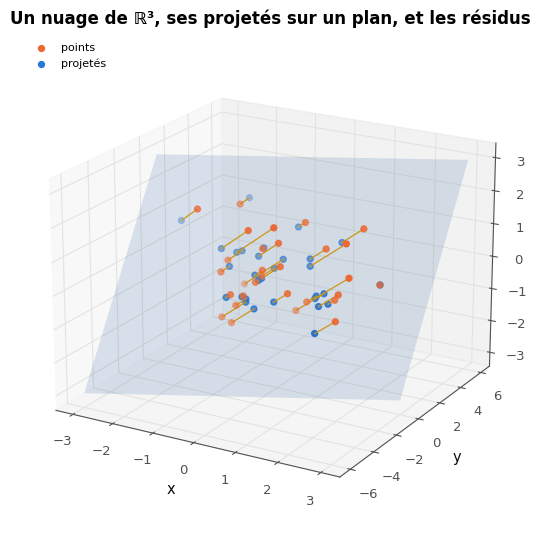

In [36]:
mymath = wbm.load_mymath("ref")


def draw_projection(ax, X, A):
    """In the 3D axis ax: the points of X (one per row), their projections on the plane spanned by the columns of A,
    and one segment from each point to its projection."""
    X, A = np.asarray(X, dtype=float), np.asarray(A, dtype=float)
    P = np.array([mymath.orthogonal.project(x, A) for x in X])
    s, t = np.meshgrid(np.linspace(-3, 3, 2), np.linspace(-3, 3, 2))
    ax.plot_surface(s * A[0, 0] + t * A[0, 1], s * A[1, 0] + t * A[1, 1], s * A[2, 0] + t * A[2, 1],
                    alpha=0.15, color="C0")
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], color="C1", s=18, label="points")
    ax.scatter(P[:, 0], P[:, 1], P[:, 2], color="C0", s=18, label="projetés")
    for x, p in zip(X, P):
        ax.plot([x[0], p[0]], [x[1], p[1]], [x[2], p[2]], color="C3", lw=0.9)
    ax.legend(loc="upper left", fontsize=8)


fig = plt.figure(figsize=(7.5, 6.5))
ax = fig.add_subplot(projection="3d")
try:
    draw_projection(ax, CLOUD_30, PLANE_30)
    ax.set(xlabel="x", ylabel="y", zlabel="z", title="Un nuage de ℝ³, ses projetés sur un plan, et les résidus")
    ax.view_init(elev=20, azim=-60)
except BaseException:
    plt.close(fig)
    raise
plt.show()

**Vérifications automatiques** (deux autres nuages, deux autres plans, dans des axes neufs).

In [37]:
with checked("M12b.30 vérifications"):
    problems = []
    ref_30 = wbm.load_mymath("ref", alias="mymath_ref").orthogonal   # your mymath stays loaded
    rng_t = np.random.default_rng(300)
    for X_t, A_t in [(rng_t.normal(size=(6, 3)), np.array([[1.0, 2.0], [0.0, 1.0], [1.0, -1.0]])),
                     (rng_t.normal(size=(4, 3)), np.array([[0.0, 1.0], [2.0, 0.0], [1.0, 1.0]]))]:
        fig_t = plt.figure()
        ax_t = fig_t.add_subplot(projection="3d")
        try:
            created = drawn(lambda: draw_projection(ax_t, X_t, A_t))
            segments = [np.column_stack(line.get_data_3d()).astype(float) for line in ax_t.lines]
        finally:
            plt.close(fig_t)
        if created:
            problems.append("draw_projection ouvre sa propre figure : dessine dans l'axe reçu")
            break
        segments = [s for s in segments if s.shape == (2, 3)]
        expected = [(x, ref_30.project(x, A_t)) for x in X_t]
        missing = [i for i, (x, p) in enumerate(expected)
                   if not any(np.allclose(s, [x, p], atol=1e-9) or np.allclose(s, [p, x], atol=1e-9) for s in segments)]
        if missing:
            try:
                project_ok = all(np.allclose(mymath.orthogonal.project(x, A_t), p, atol=1e-9) for x, p in expected)
            except Exception:  # noqa: BLE001 - a project that raises is not right either
                project_ok = False
            if not project_ok:
                problems.append("ta fonction project (M12b.25) ne rend pas le bon projeté : corrige-la d'abord, ses "
                                "tests disent ce qui ne va pas")
            else:
                problems.append(f"pour {len(X_t)} points, {len(missing)} segment(s) du point à son projeté manque(nt) "
                                "ou sont faux : un segment par point, ax.plot([x[0], p[0]], [x[1], p[1]], [x[2], p[2]])")
            break
    if problems:
        print("❌ Ex M12b.30 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M12b.30 : un segment juste par point, du point à son projeté, sur deux nuages et deux plans.")

✅ Ex M12b.30 : un segment juste par point, du point à son projeté, sur deux nuages et deux plans.


💡 Chaque segment $\mathbf{x} - \mathbf{p}$ est orthogonal au plan : sur la figure, ils sont tous parallèles à la normale $(1, -1, 1)$ du plan engendré par $(1, 1, 0)$ et $(0, 1, 1)$, ce que la perspective cache sous certains angles. Le point le plus loin du plan a le plus grand $|\mathbf{x} \cdot \mathbf{n}|/\lVert \mathbf{n} \rVert$ (M07). Changer de base du même plan ne change ni les projetés ni la figure : la projection ne dépend que du sous-espace.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §3, §5, §6 et §7. Trois erreurs à trouver, un test de propriétés, puis des moindres carrés précis sur des colonnes presque dépendantes.

### Ex M12b.31 — Chasse à l'erreur : une normalisation oubliée, QQᵀ sur une base non orthonormée, R w = Qᵀy résolu dans le mauvais sens 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques de Gram-Schmidt, de projection et de QR, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §3, §5 et §7 · **Parcours :** C

Un collègue a écrit le code suivant ; six lignes portent une lettre et un commentaire qui dit ce qu'elles doivent calculer. Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
A = np.array([[2.0, 0.0], [1.0, 3.0], [2.0, 3.0]])      # columns a1 = (2, 1, 2), a2 = (0, 3, 3)
q1 = A[:, 0] / np.linalg.norm(A[:, 0])
q2 = A[:, 1] - (A[:, 1] @ q1) * q1           # (A) the second vector of the orthonormal basis: its norm
P = A @ A.T                                  # (B) the matrix of the projection on Vect(a1, a2): P[0, 0]
Q = np.column_stack([q1, q2 / np.linalg.norm(q2)])
v = np.array([3.0, 0.0, 0.0])
r = v - Q @ (Q.T @ v)                        # (C) the residual of v after projection on Vect(a1, a2): r[0]
R = np.triu(Q.T @ A)
y = np.array([3.0, 3.0, 6.0])
z = Q.T @ y
w = np.zeros(2)
for i in range(2):                           # (D) the least squares weights, from R w = Q^T y: w[0]
    w[i] = (z[i] - R[i, :i] @ w[:i]) / R[i, i]
loss = np.abs(Q.T @ Q - np.eye(2)).max()     # (E) the loss of orthogonality of Q: about 0
c = Q.T @ A[:, 1]                            # (F) the coordinates of a2 in the basis (q1, q2): c[1]
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 4 décimales) ; pour (A), la norme du **vrai** deuxième vecteur de la base orthonormée.

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? Laquelle des trois s'exécute sans erreur **et** rend un résultat plausible, et pourquoi est-elle la plus dangereuse ?

In [38]:
answer_M12b_31a = "ABD"
A = np.array([[2.0, 0.0], [1.0, 3.0], [2.0, 3.0]])
q1 = A[:, 0] / np.linalg.norm(A[:, 0])
v2 = A[:, 1] - (A[:, 1] @ q1) * q1
q2 = v2 / np.linalg.norm(v2)                 # (A) normalize
Q = np.column_stack([q1, q2])
P = Q @ Q.T                                  # (B) Q Qᵀ with the orthonormal basis, not A Aᵀ
v = np.array([3.0, 0.0, 0.0])
r = v - Q @ (Q.T @ v)                        # (C) correct
R = np.triu(Q.T @ A)
y = np.array([3.0, 3.0, 6.0])
z = Q.T @ y
w = np.zeros(2)
for i in reversed(range(2)):                 # (D) back substitution, from the last row
    w[i] = (z[i] - R[i, i + 1:] @ w[i + 1:]) / R[i, i]
loss = np.abs(Q.T @ Q - np.eye(2)).max()     # (E) correct
c = Q.T @ A[:, 1]                            # (F) correct
answer_M12b_31b = [float(np.linalg.norm(q2)), float(P[0, 0]), float(r[0]), float(w[0]), float(loss), float(c[1])]
print(answer_M12b_31a, np.round(answer_M12b_31b, 4).tolist())

ABD [1.0, 0.8889, 0.3333, 1.6667, 0.0, 3.0]


In [39]:
wbm.record("M12b.31a", "ABD",
           mistakes={"il manque une ligne fautive : refais chaque ligne à la main, avec ses propres nombres": "BD",
                     "il manque une ligne fautive : recalcule ce que fait chaque ligne, puis compare à son commentaire": "AD",
                     "il manque une ligne fautive : vérifie chaque résultat sur un petit exemple que tu sais faire à la main": "AB",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCD", "ABDE", "ABDF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque ligne à la main, avec ses propres nombres": {"BCD", "BDE", "BDF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : recalcule ce que fait chaque ligne, puis compare à son commentaire": {"ACD", "ADE", "ADF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie chaque résultat sur un petit exemple que tu sais faire à la main": {"ABC", "ABE", "ABF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "B", "D"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"C", "E", "F", "AC", "AE", "AF", "BC", "BE", "BF", "CD", "CE", "CF", "DE", "DF", "EF", "ACE", "ACF", "AEF", "BCE", "BCF", "BEF", "CDE", "CDF", "CEF", "DEF", "ABCE", "ABCF", "ABEF", "ACDE", "ACDF", "ACEF", "ADEF", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCEF", "ACDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE", "ABCDF", "ABDEF", "ABCDEF"}})
VALUES_31 = [1.0, 8 / 9, 1 / 3, 5 / 3, 0.0, 3.0]
wbm.record("M12b.31b", VALUES_31, decimals=4,
           mistakes={"(A) : q₂ doit être normé, sa norme vaut 1": [3.0] + VALUES_31[1:],
                      "(B) : la projection est Q Qᵀ avec une base orthonormée, pas A Aᵀ": VALUES_31[:1] + [4.0] + VALUES_31[2:],
                      "(D) : R est triangulaire supérieure, on remonte depuis la dernière ligne": VALUES_31[:3] + [7 / 3] + VALUES_31[4:]})

WBM_ANSWER {"hash": "72dfcb7beba6b7182099e19fdc302840a99b28a4840f0474c9c0340831f172aa", "id": "M12b.31a", "kind": "str", "mistakes": {"0257cc71d8c825579b8c3bfb70e70a123ac039293938a67820e00002b9afdb5b": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "03f92f8f9fec844ea9e65d27ef01110fd4a72fa24e7a4d581d5f786ca7932cbc": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "05bf1ef71436f4d4c8dab1388fc52eb66c96aea85bdbcaffd8e4f4f762218975": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "066d66bd0dc3f51247be1dfb776317247eca6d6bc94e769653ebe209ea27386b": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "094df6a80cb5a30d5bb5c876c3ae5268b4aa5143ede2ab9d5b7d9fa6eeec5084": "plusieurs lignes fautives manquent : 

💡 (A) $\mathbf{a}_2 \cdot \mathbf{q}_1 = 3$ et $\mathbf{v}_2 = (0, 3, 3) - (2, 1, 2) = (-2, 2, 1)$, de norme 3 : il faut le diviser par 3. (B) $\mathbf{A}\mathbf{A}^\top$ n'est pas une projection ($\mathbf{a}_1$ et $\mathbf{a}_2$ ne sont ni unitaires ni orthogonaux) ; $\mathbf{Q}\mathbf{Q}^\top$ a pour coin $\frac{4}{9} + \frac{4}{9} = \frac{8}{9}$. (C) Juste : le résidu de $(3, 0, 0)$ est sa composante sur la normale $\frac{1}{3}(1, 2, -2)$, soit $\frac{1}{3}(1, 2, -2)$. (D) La boucle descend et ignore $r_{12}$ : elle donne $w_0 = \frac{7}{3}$ ; en remontant, $w_1 = \frac{2}{3}$ puis $w_0 = \frac{7 - 3 \times 2/3}{3} = \frac{5}{3}$. C'est la plus dangereuse : elle s'exécute et rend des poids plausibles. (E) Juste : 0 aux arrondis près. (F) Juste : $\mathbf{a}_2 = 3\mathbf{q}_1 + 3\mathbf{q}_2$.

### Ex M12b.32 — Un test de propriétés pour la projection : idempotente, symétrique, résidu orthogonal 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test fondé sur les propriétés d'une projection orthogonale, vérifiées sur des matrices aléatoires, et voir quelle propriété attrape quelle erreur.  
**Prérequis :** fiche §5 ; Ex M12b.25 · **Parcours :** C

Les tests de `mymath` comparent `project` à une référence. On peut aussi vérifier des **propriétés** que toute projection orthogonale doit avoir (fiche §5). Écris :
- `check_projection(project, seed, trials=10)` : avec `rng = np.random.default_rng(seed)`, répète `trials` fois : tire $m$ entre 2 et 6 (`rng.integers(2, 7)`), $k$ entre 1 et $m - 1$ (`rng.integers(1, m)`), une matrice $\mathbf{A}$ de forme $(m, k)$ et deux vecteurs $\mathbf{u}$, $\mathbf{v}$ de $\mathbb{R}^m$ (loi normale). Avec $\mathbf{p}$ = `project(v, A)`, vérifie par des `assert` (avec un message), à $10^{-9}$ près : (1) **idempotence** : `project(p, A)` redonne $\mathbf{p}$ ; (2) **symétrie** : $\mathbf{P}\mathbf{u} \cdot \mathbf{v} = \mathbf{u} \cdot \mathbf{P}\mathbf{v}$ ; (3) **résidu orthogonal** : $\mathbf{A}^\top(\mathbf{v} - \mathbf{p}) = \mathbf{0}$ ;
- `test_projection()` : le test au format pytest, sans argument, qui appelle `check_projection` avec **ta** fonction (`mymath.orthogonal.project`) et une graine fixe.

La cellule fournie définit deux copies fausses : une projection **oblique** (elle envoie bien sur $\operatorname{Im}\mathbf{A}$, mais pas perpendiculairement) et $\mathbf{A}\mathbf{A}^\top\mathbf{v}$ sans Gram-Schmidt. La vérification lance ton test sur la bonne projection (la référence) et sur chaque copie fausse, pour 20 graines.

Dans ta copie : quelles propriétés attrapent la projection oblique, et laquelle la laisse passer ? Même question pour $\mathbf{A}\mathbf{A}^\top\mathbf{v}$. Pourquoi $k$ doit-il rester inférieur à $m$ (que deviendrait la projection oblique pour $k = m$) ? Une fonction fausse pourrait-elle passer les trois propriétés ?

In [40]:
def project_oblique(v, A):                      # a copy with a bug: idempotent, but not orthogonal
    A = np.asarray(A, dtype=float)
    B = A + 0.5 * np.cos(np.arange(A.size)).reshape(A.shape)    # another basis, used to "aim" the projection
    return A @ np.linalg.solve(B.T @ A, B.T @ np.asarray(v, dtype=float))


def project_no_gram_schmidt(v, A):              # another bug: A Aᵀ v, without orthonormalizing A
    A = np.asarray(A, dtype=float)
    return A @ (A.T @ np.asarray(v, dtype=float))

In [41]:
mymath = wbm.load_mymath("ref")


def check_projection(project, seed, trials=10):
    """Assert idempotence, symmetry and an orthogonal residual for `project`, on `trials` random cases."""
    rng = np.random.default_rng(seed)
    for _ in range(trials):
        m = int(rng.integers(2, 7))
        k = int(rng.integers(1, m))
        A = rng.normal(size=(m, k))
        u, v = rng.normal(size=m), rng.normal(size=m)
        p = np.asarray(project(v, A), dtype=float)
        assert np.allclose(project(p, A), p, rtol=0, atol=1e-9), (
            f"expected project(p, A) = p (idempotence) for A of shape {A.shape}, got a gap of "
            f"{np.max(np.abs(np.asarray(project(p, A)) - p)):.1e}")
        left, right = float(np.asarray(project(u, A)) @ v), float(u @ p)
        assert abs(left - right) <= 1e-9 * max(1.0, abs(left)), (
            f"expected P u · v = u · P v (symmetry) for A of shape {A.shape}, got {left:.6f} and {right:.6f}")
        assert np.allclose(A.T @ (v - p), 0, rtol=0, atol=1e-9), (
            f"expected Aᵀ(v − p) = 0 (orthogonal residual) for A of shape {A.shape}, got a largest "
            f"|Aᵀ(v − p)| of {np.max(np.abs(A.T @ (v - p))):.1e}")


def test_projection():
    """The pytest test: check_projection on your project, with a fixed seed."""
    check_projection(mymath.orthogonal.project, seed=32)


test_projection()
print("the three properties hold for the reference")

the three properties hold for the reference


In [42]:
with checked("M12b.32 vérifications"):
    problems = []
    ref_32 = wbm.load_mymath("ref", alias="mymath_ref").orthogonal   # your mymath stays loaded

    def outcome(project_t, seed):
        """None if check_projection passes, else the message of its AssertionError."""
        try:
            check_projection(project_t, seed)
        except AssertionError as exc:
            return str(exc)
        return None

    passed = sum(outcome(ref_32.project, seed) is None for seed in range(20))
    caught_oblique = [outcome(project_oblique, seed) for seed in range(20)]
    caught_aat = [outcome(project_no_gram_schmidt, seed) for seed in range(20)]
    print(f"la bonne projection passe ton test {passed} fois sur 20 ; la projection oblique est attrapée "
          f"{sum(m is not None for m in caught_oblique)} fois sur 20 ; A Aᵀ v, "
          f"{sum(m is not None for m in caught_aat)} fois sur 20")
    if passed < 20:
        problems.append("ton test échoue sur la bonne projection : compare avec np.allclose (des flottants), et "
                        "vérifie tes formes")
    if sum(m is not None for m in caught_oblique) < 20:
        problems.append("ton test laisse passer la projection oblique : vérifie aussi la symétrie, ou que le résidu "
                        "est orthogonal aux colonnes")
    if sum(m is not None for m in caught_aat) < 20:
        problems.append("ton test laisse passer A Aᵀ v : vérifie aussi que projeter deux fois ne change rien")
    if not problems and any(not (m or "").strip() for m in caught_oblique + caught_aat):
        problems.append("ajoute un message à chaque assert (assert condition, message)")
    if not problems:
        try:
            test_projection()
        except AssertionError as exc:
            problems.append(f"test_projection échoue sur ta librairie : {exc}")
    if problems:
        print("❌ Ex M12b.32 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M12b.32 : ton test passe sur la bonne projection et attrape les deux copies fausses.")

la bonne projection passe ton test 20 fois sur 20 ; la projection oblique est attrapée 20 fois sur 20 ; A Aᵀ v, 20 fois sur 20
✅ Ex M12b.32 : ton test passe sur la bonne projection et attrape les deux copies fausses.


💡 La projection oblique est idempotente ($\mathbf{P}^2 = \mathbf{P}$) : (1) la laisse passer ; elle n'est pas symétrique, et son résidu n'est pas orthogonal aux colonnes : (2) et (3) l'attrapent. $\mathbf{A}\mathbf{A}^\top$ est symétrique : (2) la laisse passer ; elle n'est pas idempotente (sauf si $\mathbf{A}$ a des colonnes orthonormées), et son résidu n'est pas orthogonal : (1) et (3) l'attrapent. Pour $k = m$, $\operatorname{Im}\mathbf{A} = \mathbb{R}^m$ et toute projection sur $\mathbb{R}^m$ est l'identité : la copie oblique serait juste. Une matrice symétrique et idempotente est une projection orthogonale ; (3) vérifie en plus que c'est la bonne : sur $\operatorname{Im}\mathbf{A}$. Les trois propriétés ensemble caractérisent la projection orthogonale sur $\operatorname{Im}\mathbf{A}$ dès que $\mathbf{p} \in \operatorname{Im}\mathbf{A}$, ce qu'un test pourrait vérifier aussi.

### Ex M12b.33 — Défi : des colonnes presque dépendantes, des moindres carrés à 1e−8 près de `lstsq` par l'orthogonalisation de [X | y] 🏆 ★★★ ⏱️ 30 min
**Objectif :** résoudre des moindres carrés aussi précisément qu'une bibliothèque sur des données dont deux colonnes sont presque dépendantes, là où les équations normales et la QR naïve échouent.  
**Prérequis :** fiche §6 et §7 ; Ex M12b.24, M12b.26 et M12b.29 · **Parcours :** C

La fonction fournie `make_nearly_dependent(seed)` fabrique un tableau de 200 exemples et 6 features dont les deux dernières ne diffèrent que de $10^{-6}$ fois un bruit, et une cible presque exactement linéaire. Sur ces données, les équations normales et ta fonction `least_squares_qr` (Gram-Schmidt modifié, $\mathbf{R} = \mathbf{Q}^\top\mathbf{X}$, puis $\mathbf{Q}^\top\mathbf{y}$) s'écartent de `np.linalg.lstsq` d'environ $10^{-5}$ à $10^{-3}$ : la vérification l'affiche.

**L'objectif** : écrire `least_squares_stable(X, y)`, qui rend des poids à moins de $10^{-8}$ (le plus grand écart, coordonnée par coordonnée) de ceux de `np.linalg.lstsq` sur les trois datasets `seed` = 33, 34 et 35, **sans** `np.linalg.lstsq`, `qr`, `pinv`, `inv`, `svd`, `cholesky` ni `scipy`. Une dernière cellule enregistre si l'objectif est atteint.

Pistes (Björck, 1967) : applique le procédé **modifié** à la matrice augmentée $[\mathbf{X} \mid \mathbf{y}]$, de forme $(n, p + 1)$, en gardant les coefficients **au moment où tu les retires** : pour la colonne $k$, $r_{jk} = \mathbf{q}_j \cdot \mathbf{v}$ (le vecteur courant) pour $j < k$, puis $r_{kk} = \lVert \mathbf{v} \rVert$. La dernière colonne de ce $\mathbf{R}$ de forme $(p + 1, p + 1)$ contient, au-dessus de la diagonale, le second membre $\mathbf{z}$ ; résous $\mathbf{R}_{[:p, :p]}\,\mathbf{w} = \mathbf{z}_{[:p]}$ en remontant. Ne recalcule ni $\mathbf{R}$ par $\mathbf{Q}^\top\mathbf{X}$ ni $\mathbf{z}$ par $\mathbf{Q}^\top\mathbf{y}$ : c'est là que la QR naïve perd sa précision.

Dans ta copie : pourquoi $\mathbf{R} = \mathbf{Q}^\top\mathbf{X}$, recalculé après coup, est-il moins précis que les coefficients gardés pendant le procédé (pense à M12b.28 : $\mathbf{Q}$ n'est plus tout à fait orthonormée) ? Que représente le dernier élément diagonal de $\mathbf{R}$, $r_{p+1,p+1}$ ? Une autre voie marche-t-elle (pense à M12b.29) ?

In [43]:
def make_nearly_dependent(seed, n=200, p=6):
    """A (n, p) design matrix whose last column is the one before plus 1e-6 times some noise, and noisy targets."""
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, p))
    X[:, p - 1] = X[:, p - 2] + 1e-6 * rng.normal(size=n)
    w_true = rng.normal(size=p)
    y = X @ w_true + 1e-6 * rng.normal(size=n)
    return X, y

In [44]:
mymath = wbm.load_mymath("ref")


def least_squares_stable(X, y):
    """The least squares weights of y on X, within 1e-8 of np.linalg.lstsq even for nearly dependent columns."""
    V = np.column_stack([np.asarray(X, dtype=float), np.asarray(y, dtype=float)])   # a copy: [X | y]
    n, p1 = V.shape
    R = np.zeros((p1, p1))
    for k in range(p1):                          # modified Gram-Schmidt, the coefficients kept as they are removed
        for j in range(k):
            R[j, k] = V[:, j] @ V[:, k]
            V[:, k] -= R[j, k] * V[:, j]
        R[k, k] = np.linalg.norm(V[:, k])
        V[:, k] /= R[k, k]
    p = p1 - 1
    w = np.zeros(p)
    for i in reversed(range(p)):                 # back substitution: R[:p, :p] w = z, z = R[:p, p]
        w[i] = (R[i, p] - R[i, i + 1:p] @ w[i + 1:]) / R[i, i]
    return w


X_33, y_33 = make_nearly_dependent(33)
print("|y − X w| :", float(np.linalg.norm(y_33 - X_33 @ least_squares_stable(X_33, y_33))))

|y − X w| : 1.4191445546793836e-05


In [45]:
wbm.record("M12b.33", True,
           mistakes={"l'objectif n'est pas atteint sur les trois datasets : la cellule du défi dit pourquoi": False})

WBM_ANSWER {"hash": "fdc0920fdec931a016bfdde923fc9878a26345abc8fcdbe5b6438bf9c4f9793f", "id": "M12b.33", "kind": "bool", "mistakes": {"89503e65a68d78d6021ea7aafe277684b4be7cade38a4b868e34ab2e84dbed35": "l'objectif n'est pas atteint sur les trois datasets : la cellule du défi dit pourquoi"}}
📝 Ex M12b.33 : réponse enregistrée (bool).


In [46]:
with checked("M12b.33 défi"):
    problems, ok_33 = [], False
    ref_33 = wbm.load_mymath("ref", alias="mymath_ref").orthogonal   # your mymath stays loaded
    for seed_t in (33, 34, 35):
        X_t, y_t = make_nearly_dependent(seed_t)
        w_ref = np.linalg.lstsq(X_t, y_t, rcond=None)[0]
        try:
            w_t = np.asarray(least_squares_stable(X_t.copy(), y_t.copy()), dtype=float)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"least_squares_stable lève {type(exc).__name__} ({exc})")
            break
        if w_t.shape != w_ref.shape:
            problems.append(f"données {seed_t} : least_squares_stable rend la forme {w_t.shape}, pas {w_ref.shape}")
            break
        gap = float(np.max(np.abs(w_t - w_ref)))
        gap_normal = float(np.max(np.abs(np.linalg.solve(X_t.T @ X_t, X_t.T @ y_t) - w_ref)))
        gap_qr = float(np.max(np.abs(ref_33.least_squares_qr(X_t, y_t) - w_ref)))
        print(f"données {seed_t} : écart à lstsq {gap:.1e} (équations normales {gap_normal:.1e}, "
              f"least_squares_qr {gap_qr:.1e})")
        if not gap <= 1e-8:
            problems.append(f"données {seed_t} : écart {gap:.1e} à lstsq, au-dessus de 1e-8")
            break
    if problems:
        print("❌ Ex M12b.33 : " + " ; ".join(problems) + ".")
    else:
        ok_33 = True
        print("✅ Ex M12b.33 : défi réussi : à moins de 1e-8 de lstsq sur les trois datasets.")

données 33 : écart à lstsq 8.0e-12 (équations normales 6.0e-06, least_squares_qr 1.8e-04)
données 34 : écart à lstsq 5.9e-11 (équations normales 4.1e-04, least_squares_qr 4.0e-05)
données 35 : écart à lstsq 6.3e-11 (équations normales 5.6e-04, least_squares_qr 2.7e-04)
✅ Ex M12b.33 : défi réussi : à moins de 1e-8 de lstsq sur les trois datasets.


💡 La QR naïve calcule $\mathbf{Q}$ par le procédé modifié, qui perd un peu d'orthogonalité (de l'ordre de $10^{-10}$ ici, M12b.28) ; recalculer $\mathbf{R} = \mathbf{Q}^\top\mathbf{X}$ après coup mélange cet écart au petit élément $r_{66} \approx 10^{-5}$, qui mesure la presque dépendance des deux dernières colonnes, et l'erreur relative sur $r_{66}$ devient de l'ordre de $10^{-4}$. Les coefficients gardés pendant le procédé, eux, vérifient $\mathbf{X} = \mathbf{Q}\mathbf{R}$ aux arrondis près, même quand $\mathbf{Q}$ n'est plus tout à fait orthonormée, et traiter $\mathbf{y}$ comme une colonne de plus donne un $\mathbf{z}$ cohérent avec eux : c'est le résultat de Björck (1967). $r_{p+1,p+1} = \lVert \mathbf{y} - \mathbf{X}\mathbf{w}^* \rVert$ est la norme du résidu. Autre voie : orthogonaliser deux fois (M12b.29), pour un $\mathbf{Q}$ orthonormé à $10^{-16}$ près ; alors $\mathbf{Q}^\top\mathbf{X}$ et $\mathbf{Q}^\top\mathbf{y}$ redeviennent précis.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu reconnaître un produit scalaire, et calculer normes et angles avec ?
2. Sais-tu lire des coordonnées dans une base orthonormée, et reconnaître une matrice orthogonale ?
3. Sais-tu orthonormaliser une famille par Gram-Schmidt ?
4. Sais-tu calculer un complément orthogonal, une projection et une distance à un sous-espace ?
5. Sais-tu résoudre des moindres carrés par une projection, puis par QR ?

**La suite** : le chapitre 12 de workbookIA (préparation des données), en parallèle de M12c, les valeurs propres et les matrices symétriques.